<a href="https://colab.research.google.com/github/daniswaramp/steel-plate-cooling-fdm/blob/main/ACC_Heat_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Accelerated cooling simulation of a hot-rolled plate on a laminar cooling line

## Empirical calculation and a 3-D finite difference heat transfer analysis

This notebook follows a hot-rolled steel plate from the finishing mill to the cooling bed and answers one question: how different are the temperatures at the surface, at quarter depth (1/4), at one-third depth (1/3) and at the core, during and after accelerated cooling?

The journey:

1. The plate leaves the finish rolling mill at the finish rolling temperature (FRT).
2. It travels down the run-out table at the table run speed, passing under laminar water curtains, `n_cur` headers on top and `n_cur` on the bottom, spaced `s_gap` apart along the table.
3. Each curtain impinges a strip of cooling water onto the plate. Between curtains, and after the last one, the plate cools slowly by air convection and radiation.
4. Water cooling is fierce, of order thousands of W/m²K, while steel conducts heat slowly (α ≈ 6×10⁻⁶ m²/s), so the surface cools far faster than the core and a through-thickness gradient builds.
5. An empirical module pre-calculates the water flux, the boiling-regime heat transfer coefficient, the Biot number and three analytical estimates: lumped capacitance, semi-infinite solid and Heisler one-term.
6. A 3-D explicit finite difference (FDM) solver resolves the full transient temperature field `T(thickness, width, length, t)` with the moving-curtain boundary condition, and slices it in every direction.

Run all cells top to bottom. The notebook needs only `numpy` and `matplotlib`, and Colab has both already.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import math, os
import pathlib, urllib.request
from math import erfc, pi, tan
from IPython.display import Markdown, display, HTML

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "figure.facecolor": "white"})
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)
print("numpy", np.__version__, "| matplotlib", mpl.__version__)

numpy 2.4.6 | matplotlib 3.11.2


## 1 · Inputs, the only cell you need to edit

These are the process constraints: plate geometry, header count per side (`n_cur = 1` means 1 top and 1 bottom), table run speed, finish rolling temperature and the uniform header spacing. The next cell holds everything else fixed. The `tune_factor` rescales the water-side HTC, so keep it at 1.0 for the pure prediction, or calibrate it (section 9) when the line behaves more or less severely than the correlation suggests.

The chemistry of the grade sits in the same cell. Everything downstream that depends on the steel rather than the line reads it from there: the transformation temperatures, the phase screen in section 16 and the equilibrium calculation in section 3.


In [2]:
t_h    = 25.0      # plate thickness                                [mm]
W      = 2000.0    # plate width                                    [mm]
L      = 12000.0   # plate length                                   [mm]
n_cur  = 5         # header curtain number (per side: 5 -> 5 top + 5 bottom)
v      = 60.0      # table run speed during cooling                 [m/min]
FRT    = 880.0     # finish rolling temperature (before laminar)    [degC]
s_gap  = 3000.0    # header spacing (uniform gap between headers)   [mm]
tune_factor = 1.0  # HTC tuning factor: >1 = more severe cooling than predicted,
                    #                   <1 = less severe than predicted  [-]

# chemistry of the grade, weight percent. The transformation temperatures, the CCT-style
# phase screen and the equilibrium calculation all follow from these, so put your own heat here.
chem = dict(
    C  = 0.09,     # carbon
    Mn = 1.45,     # manganese
    Si = 0.25,     # silicon
    Cr = 0.03,     # chromium
    Mo = 0.005,    # molybdenum
    Ni = 0.02,     # nickel
    Cu = 0.02,     # copper
    Nb = 0.035,    # niobium
    Ti = 0.015,    # titanium
    V  = 0.005,    # vanadium
    N  = 0.006,    # nitrogen
    Al = 0.035,    # aluminium
    S  = 0.005,    # sulphur
    P  = 0.015,    # phosphorus
    B  = 0.0,      # boron
)

print(f"Plate {t_h:.0f} x {W:.0f} x {L:.0f} mm | {n_cur} top + {n_cur} bottom curtains | "
      f"{v:.0f} m/min | FRT {FRT:.0f} degC | spacing {s_gap:.0f} mm | tune_factor {tune_factor:.2f}")
print("Grade " + "  ".join(f"{k} {val:g}" for k, val in sorted(chem.items())))


Plate 25 x 2000 x 12000 mm | 5 top + 5 bottom curtains | 60 m/min | FRT 880 degC | spacing 3000 mm | tune_factor 1.00
Grade Al 0.035  B 0  C 0.09  Cr 0.03  Cu 0.02  Mn 1.45  Mo 0.005  N 0.006  Nb 0.035  Ni 0.02  P 0.015  S 0.005  Si 0.25  Ti 0.015  V 0.005


## 2 · Chemistry: what this grade is able to form

The thermal model gives the cooling rate at each depth. What that rate produces is a question about the steel, so the chemistry lives in the inputs cell (section 1) along with the process settings, and everything downstream that depends on the steel reads it from there. The defaults are:

| C | Si | Mn | P | S | Al | N | Cr | Mo | Ni | Cu | V | Nb | Ti |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.09 | 0.25 | 1.45 | 0.015 | 0.005 | 0.035 | 0.006 | 0.03 | 0.005 | 0.02 | 0.02 | 0.005 | 0.035 | 0.015 |

Two independent routes are taken to the transformation temperatures. The first is the set of standard empirical relations, which are quick and carry every element including the microalloying ones.

- $Ac_1 = 739 - 22C - 7Mn + 2Si + 14Cr + 13Mo - 13Ni + 20V$ (Brandis, 1975)
- $Ac_3 = 910 - 203\sqrt{C} - 15.2Ni + 44.7Si + 104V + 31.5Mo + 13.1W$ (Andrews, 1965)
- $Ar_3 = 910 - 203\sqrt{C} - 30Mn + 44.7Si - 11Cr + 31.5Mo - 15.2Ni$ ($Ae_3$-style form, cooling start)
- $B_s = 830 - 270C - 90Mn - 37Ni - 70Cr - 83Mo$ (Steven and Haynes, 1956)
- $M_s = 561 - 474C - 33Mn - 17Cr - 17Ni - 21Mo$ (Steven and Haynes, 1956)
- $\log_{10} V_{c90} = 2.94 - 0.75\beta$ with $\beta = 2.7C + 0.4Si + Mn + 0.45Ni + 0.8Cr + 2Mo$ for boron-treated steel, or $\log_{10} V_{c90} = 3.69 - 0.75\beta'$ with $\beta' = 2.7C + 0.4Si + Mn + 0.45Ni + 0.8Cr + Mo$ for boron-free steel (Ueno and Itoh, 1988)

$V_{c90}$ is the cooling rate that leaves 90 percent martensite. Ueno and Itoh give it in two forms: one for boron-treated steel, with free boron at or above 5 ppm and twice the molybdenum coefficient, and one for boron-free steel, which takes a higher constant and half the molybdenum coefficient. This grade carries no boron, so the second form applies. The code picks between them from the chemistry rather than assuming one.

Andrews published $Ae_3$, $Ac_1$ and $Ac_3$ and no ferrite-start temperature for cooling, so the $Ar_3$ line below is the $Ae_3$-style expression read as a start temperature: it carries the manganese and chromium terms of $Ae_3$ that $Ac_3$ does not, which is most of the gap between the two.

The second route is a thermodynamic calculation, in the next cell, which solves the equilibrium between austenite, ferrite and the carbides for the same composition and returns the phase fractions against temperature. Run both and compare: agreement within a few tens of degrees is the useful check, and where they disagree the equilibrium result is the one with a database behind it while the empirical one is the one that knows about the hot rolling.


In [3]:
# the chemistry comes from the inputs cell (section 1)
KEYS = ("C", "Si", "Mn", "P", "S", "Al", "N", "Cr", "Mo", "Ni", "Cu", "V", "Nb", "Ti", "W", "B")
c = {k: float(chem.get(k, 0.0)) for k in KEYS}
missing = [k for k in ("C", "Mn", "Si", "Nb", "Ti") if chem.get(k) is None]
if missing:
    print("chemistry is missing", ", ".join(missing), ": the defaults of 0 have been used for them")

Ac1 = 739 - 22*c["C"] - 7*c["Mn"] + 2*c["Si"] + 14*c["Cr"] + 13*c["Mo"] - 13*c["Ni"] + 20*c["V"]
Ac3 = 910 - 203*np.sqrt(c["C"]) - 15.2*c["Ni"] + 44.7*c["Si"] + 104*c["V"] + 31.5*c["Mo"] + 13.1*c["W"]
Ar3 = 910 - 203*np.sqrt(c["C"]) - 30*c["Mn"] + 44.7*c["Si"] - 11*c["Cr"] + 31.5*c["Mo"] - 15.2*c["Ni"]
Bs  = 830 - 270*c["C"] - 90*c["Mn"] - 37*c["Ni"] - 70*c["Cr"] - 83*c["Mo"]
Ms  = 561 - 474*c["C"] - 33*c["Mn"] - 17*c["Cr"] - 17*c["Ni"] - 21*c["Mo"]

# Ueno and Itoh give the critical rate in two forms. The one with the 2 Mo coefficient is for
# boron-treated steel (free boron 5 ppm or more). A boron-free steel takes the 3.69 constant
# with the molybdenum coefficient halved, which for this grade is several times the rate.
free_B_ppm = c["B"] * 1e4                      # wt percent -> ppm
if free_B_ppm >= 5.0:
    beta = 2.7*c["C"] + 0.4*c["Si"] + c["Mn"] + 0.45*c["Ni"] + 0.8*c["Cr"] + 2*c["Mo"]
    Vc90 = 10.0 ** (2.94 - 0.75*beta)
    Vc90_form = "boron-treated"
else:
    beta = 2.7*c["C"] + 0.4*c["Si"] + c["Mn"] + 0.45*c["Ni"] + 0.8*c["Cr"] + c["Mo"]
    Vc90 = 10.0 ** (3.69 - 0.75*beta)
    Vc90_form = "boron-free"

# nitrogen not already locked up by titanium. The mass ratio 3.5 is the convention the
# handbook table prints for this regression (Nt - Ti/3.5); the paper itself takes the
# nitrogen in solution and sets it to zero when the titanium pins all of it
N_free = max(c["N"] - c["Ti"] / 3.5, 0.0)

def Ar3_mintz(CR_per_s):
    """Ferrite start temperature from the Mintz regression, cooling rate in degC/s.

    The cooling-rate coefficient is 0.084 per degC/min in the paper, which over the fitted
    band of 10 to 200 degC/min is the 25 degC decrease the paper itself reports. The
    handbook compilation prints 0.0084 for the same equation, which would give under 2 degC
    across that band, so 0.084 is used here.
    """
    CR_per_min = max(CR_per_s, 1e-6) * 60.0
    return (862 - 182*c["C"] - 76.1*c["Mn"] + 1121*c["S"] - 1804*c["Nb"]
            + 1168*c["Ti"] - 2852*N_free - 0.084*CR_per_min)

# Andrews published Ae3, Ac1 and Ac3 and no Ar3, so the cooling-start line below is the
# Ae3-style expression rather than a transcription of a published ferrite-start relation
labels = [("Ac1 (Brandis)", Ac1), ("Ac3 (Andrews)", Ac3), ("Ar3 (Ae3-style form)", Ar3),
          ("Bs (Steven and Haynes)", Bs), ("Ms (Steven and Haynes)", Ms)]
print(f"carbon equivalent beta  {beta:.2f}   ({Vc90_form} form of the Vc90 relation)")
print(f"Vc90, rate for 90% martensite  {Vc90:.1f} degC/s   "
      f"(boron {c['B']:g} wt percent, so the {Vc90_form} form applies)")
for name, val in labels:
    print(f"{name:<24} {val:6.1f} degC")


carbon equivalent beta  1.83   (boron-free form of the Vc90 relation)
Vc90, rate for 90% martensite  207.4 degC/s   (boron 0 wt percent, so the boron-free form applies)
Ac1 (Brandis)             727.7 degC
Ac3 (Andrews)             860.6 degC
Ar3 (Ae3-style form)      816.3 degC
Bs (Steven and Haynes)    671.9 degC
Ms (Steven and Haynes)    469.5 degC


## 3 · Equilibrium phases from a thermodynamic database

The empirical relations are quick and carry every element, but they are regressions. The same chemistry can also be solved for equilibrium, which is what this cell does.


### Equilibrium phase fractions, mole fraction of all phases

| Temperature [degC] | BCC_A2 | CEMENTITE | FCC_A1 |
|---|---|---|---|
| 980 | 0.000 | 0.000 | 1.000 |
| 960 | 0.000 | 0.000 | 1.000 |
| 940 | 0.000 | 0.000 | 1.000 |
| 920 | 0.000 | 0.000 | 1.000 |
| 900 | 0.000 | 0.000 | 1.000 |
| 880 | 0.000 | 0.000 | 1.000 |
| 860 | 0.000 | 0.000 | 1.000 |
| 840 | 0.000 | 0.000 | 1.000 |
| 820 | 0.265 | 0.000 | 0.735 |
| 800 | 0.474 | 0.000 | 0.526 |
| 780 | 0.614 | 0.000 | 0.386 |
| 760 | 0.709 | 0.000 | 0.291 |
| 740 | 0.774 | 0.000 | 0.226 |
| 720 | 0.822 | 0.000 | 0.178 |
| 700 | 0.857 | 0.000 | 0.143 |
| 680 | 0.985 | 0.015 | 0.001 |
| 660 | 0.984 | 0.015 | 0.001 |
| 640 | 0.984 | 0.015 | 0.001 |
| 620 | 0.984 | 0.015 | 0.001 |
| 600 | 0.984 | 0.015 | 0.001 |
| 580 | 0.984 | 0.016 | 0.001 |
| 560 | 0.983 | 0.016 | 0.001 |
| 540 | 0.983 | 0.016 | 0.001 |
| 520 | 0.983 | 0.016 | 0.001 |
| 500 | 0.983 | 0.016 | 0.001 |

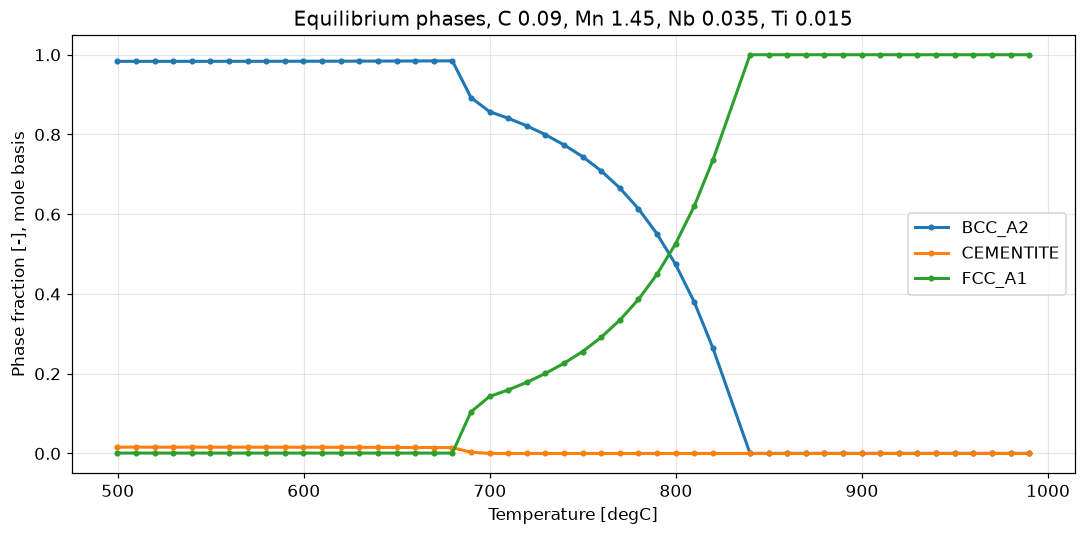

temperatures solved: 49 of 50   (1 did not converge and are skipped)
Ae3, austenite field begins:  839.1 degC   (empirical Ac3 860.6, Ar3 816.3)
A1,  cementite dissolves:    683.8 degC   (empirical Ac1 727.7)


In [4]:
# equilibrium phases against temperature from the MatCalc steel database, read by pycalphad.
# pycalphad is not part of the numpy and matplotlib pair the rest of the notebook needs, so this
# cell stands alone and falls back to the empirical temperatures when it is missing:
#     pip install pycalphad
# The database is the pycalphad port of MatCalc mc_fe v2.062, released by TU Wien under the Open
# Database Licence, and it is fetched on first use rather than copied into this repository.
TDB_URL = ("https://raw.githubusercontent.com/adityamoolya/maraging-steel-calphad/"
           "master/2databases/mc_fe_v2062_clean.tdb")
TDB_PATH = pathlib.Path("databases/mc_fe_v2062_clean.tdb")

# Elements the equilibrium calculation keeps. Vanadium, sulphur and phosphorus are left out on
# purpose: the database's models for them make the pycalphad solver fail when they are combined
# with this chemistry. All three sit below 0.05 wt percent here, so the austenite and ferrite
# boundaries barely move, and the empirical relations in the previous cell do carry them.
EQ_ELEMENTS = ["C", "Mn", "Si", "Cr", "Mo", "Ni", "Cu", "Nb", "Ti", "N", "Al"]
# The set carries no niobium, titanium or vanadium carbide or nitride. Those additions are
# deliberate omissions rather than findings: without them the calculation puts the whole of
# the Nb, Ti and V into solution by construction, so it says nothing about precipitation and
# the carbide boundaries it returns are those of a steel whose microalloying is dissolved.
EQ_PHASES = ["FCC_A1", "BCC_A2", "CEMENTITE", "M23C6", "M7C3", "M6C"]
ATOMIC = dict(Fe=55.845, C=12.011, Mn=54.938, Si=28.085, Cr=51.996, Mo=95.95, Ni=58.693,
              Cu=63.546, Nb=92.906, Ti=47.867, N=14.007, Al=26.982)

Ae3, A1, eq_T, eq_frac = None, None, None, None
heavy = [k for k in ("V", "S", "P") if c.get(k, 0.0) > 0.05]
if heavy:
    print("note: " + ", ".join(heavy) + " is above 0.05 wt percent and is not in the equilibrium")
    print("      calculation, so the boundaries below are those without " + ", ".join(heavy) + ".")

try:
    # the variables module is aliased away from v, which is the table speed in the inputs cell
    from pycalphad import Database, equilibrium as _equilibrium, variables as pcv
except Exception as exc:
    print(f"pycalphad is not available ({exc}), so the equilibrium annex is skipped.")
    print("install it with   pip install pycalphad   and re-run this cell.")
else:
    TDB_PATH.parent.mkdir(exist_ok=True)
    if not TDB_PATH.exists():
        urllib.request.urlretrieve(TDB_URL, TDB_PATH)
        print(f"fetched {TDB_PATH.name} into {TDB_PATH.parent}")

    wt = {k: c.get(k, 0.0) for k in EQ_ELEMENTS}
    wt["Fe"] = 100.0 - sum(c.get(k, 0.0) for k in KEYS)
    mol = {k: wt[k] / ATOMIC[k] for k in wt}
    total = sum(mol.values())
    comps = ["FE"] + [k.upper() for k in EQ_ELEMENTS] + ["VA"]
    cond = {pcv.X(k.upper()): mol[k] / total for k in EQ_ELEMENTS}
    cond[pcv.T] = (773.0, 1273.0, 10.0)          # pycalphad works in kelvin
    cond[pcv.P] = 101325.0
    cond[pcv.N] = 1.0

    try:
        import warnings
        with warnings.catch_warnings():       # the ported database warns about its own syntax
            warnings.simplefilter("ignore")
            res = _equilibrium(Database(str(TDB_PATH)), comps, EQ_PHASES, cond, verbose=False)
    except Exception as exc:
        print("the equilibrium calculation did not finish:", exc)
    else:
        NP = np.atleast_2d(res.NP.values.squeeze())
        PH = np.atleast_2d(res.Phase.values.squeeze())
        eq_T = np.atleast_1d(res.T.values.squeeze()).astype(float) - 273.15

        names = sorted({str(p).strip() for p in PH.ravel() if str(p).strip()})
        eq_frac = {n: np.full(eq_T.size, np.nan) for n in names}
        for i in range(eq_T.size):
            for j in range(NP.shape[1]):
                n = str(PH[i, j]).strip()
                if n and np.isfinite(NP[i, j]):
                    eq_frac[n][i] = float(NP[i, j]) if np.isnan(eq_frac[n][i]) else eq_frac[n][i] + float(NP[i, j])
        # a temperature that failed to solve shows up as fractions that do not sum to one
        ok = np.array([i for i in range(eq_T.size)
                       if abs(np.nansum([eq_frac[n][i] for n in names]) - 1.0) < 1e-3])
        for n in names:                       # absent at a temperature means zero, not unknown
            eq_frac[n][ok] = np.nan_to_num(eq_frac[n][ok], nan=0.0)

        def boundary(phase, level=0.01):
            """Highest temperature at which the phase is still above level, interpolated."""
            y = eq_frac.get(phase)
            if y is None or ok.size < 2:
                return None
            order = np.argsort(eq_T[ok]); x = eq_T[ok][order]; y = y[ok][order]
            inside = np.where(y > level)[0]
            if inside.size == 0:
                return None
            j = int(inside[-1])
            if j + 1 >= x.size:
                return float(x[j])
            x0, x1, y0, y1 = x[j], x[j + 1], y[j], y[j + 1]
            return float(x0 + (level - y0) * (x1 - x0) / (y1 - y0)) if y1 != y0 else float(x0)

        Ae3 = boundary("BCC_A2")      # ferrite disappears upwards: the austenite field starts here
        A1 = boundary("CEMENTITE")    # cementite dissolves here

        rows = ["| Temperature [degC] | " + " | ".join(names) + " |", "|---" * (len(names) + 1) + "|"]
        for i in sorted(ok, key=lambda i: -eq_T[i]):
            if abs(eq_T[i] - round(eq_T[i] / 20.0) * 20.0) < 5.0:
                body = " | ".join("" if np.isnan(eq_frac[n][i]) else f"{eq_frac[n][i]:.3f}" for n in names)
                rows.append(f"| {eq_T[i]:.0f} | {body} |")
        display(Markdown("### Equilibrium phase fractions, mole fraction of all phases\n\n" + "\n".join(rows)))

        fig, ax = plt.subplots(figsize=(10, 5))
        for n in names:
            ax.plot(eq_T[ok], eq_frac[n][ok], lw=2, marker="o", ms=3, label=n)
        ax.set_xlabel("Temperature [degC]"); ax.set_ylabel("Phase fraction [-], mole basis")
        ax.set_title("Equilibrium phases, " + ", ".join(f"{k} {c.get(k, 0):g}" for k in ("C", "Mn", "Nb", "Ti")))
        ax.legend(); fig.tight_layout(); fig.savefig(f"{FIGDIR}/equilibrium_phases.png", dpi=150)
        plt.show()

        print(f"temperatures solved: {ok.size} of {eq_T.size}"
              + ("" if ok.size == eq_T.size else f"   ({eq_T.size - ok.size} did not converge and are skipped)"))
        print(f"Ae3, austenite field begins: {Ae3:6.1f} degC   (empirical Ac3 {Ac3:.1f}, Ar3 {Ar3:.1f})")
        print(f"A1,  cementite dissolves:   {A1:6.1f} degC   (empirical Ac1 {Ac1:.1f})" if A1 is not None
              else "A1: cementite never reaches one percent in this calculation")


## 4 · The physics: transient heat conduction

### 1.1 Fourier's law of conduction

$$q = -k\,\nabla T$$

### 1.2 The heat diffusion equation (3-D, constant properties)

$$\rho\,c_p\,\frac{\partial T}{\partial t}
= k\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}+\frac{\partial^2 T}{\partial z^2}\right)
\quad\Longleftrightarrow\quad
\frac{\partial T}{\partial t}=\alpha\,\nabla^{2}T,
\qquad \alpha=\frac{k}{\rho c_p}$$

with the plate axes x = thickness, y = width, z = length (rolling direction).

### 1.3 Boundary conditions

Convection, Newton's law of cooling, applies under the water curtains ($T_f = T_w$) and in air ($T_f = T_\infty$):

$$-k\,\frac{\partial T}{\partial n}\bigg|_{s} = h\,\left(T_s - T_f\right)$$

Radiation (Stefan-Boltzmann) matters on hot air-exposed surfaces:

$$q_{rad}=\varepsilon\,\sigma\left(T_s^{4}-T_f^{4}\right),
\qquad \sigma = 5.670\times10^{-8}\ \mathrm{W/m^2K^4}$$

The two combine into an effective film coefficient, with both temperatures absolute:

$$h_{eff}=h_{conv}+\varepsilon\,\sigma\left(T_s^{2}+T_f^{2}\right)\left(T_s+T_f\right)$$

$T_s$ and $T_f$ are in kelvin, because that factorisation is what $\varepsilon\sigma(T_s^4-T_f^4)$ becomes. Evaluated in degrees Celsius it understates the coefficient several-fold: 32 W/m²K against 94 W/m²K at an 880 °C surface facing a 30 °C sink. The solver converts before it evaluates.

The symmetry plane at the plate centre-line in width carries zero flux, $\partial T/\partial n = 0$, so only half the width needs to be modelled.

### 1.4 Dimensionless numbers

$$\text{Biot: } Bi=\frac{h\,(t_h/2)}{k}
\qquad\qquad
\text{Fourier: } Fo=\frac{\alpha\,t}{(t_h/2)^2}$$

Below $Bi = 0.1$ the plate behaves almost as a lumped system. For $Bi \gg 0.1$ the internal gradients are strong and the full finite difference solution is required.

### 1.5 Analytical solutions (benchmarks for the FDM)

Lumped capacitance, exact for $Bi<0.1$:

$$\frac{T-T_\infty}{T_i-T_\infty}=\exp\!\left(-\frac{t}{\tau}\right)=\exp(-Bi\cdot Fo),
\qquad \tau=\frac{\rho c_p V}{h A}=\frac{\rho c_p (t_h/2)}{h}$$

Semi-infinite solid with a convective surface, which gives the surface response during the short first curtain contact ($\beta = \tfrac{h}{k}\sqrt{\alpha t}$):

$$\frac{T_s-T_\infty}{T_i-T_\infty}
=\exp\!\left(\frac{h^{2}\alpha t}{k^{2}}\right)\mathrm{erfc}\!\left(\frac{h\sqrt{\alpha t}}{k}\right)$$

Heisler one-term approximation, for the mid-plane of a plate suddenly exposed to $h$ on both faces, with $\zeta_1\tan\zeta_1 = Bi$ and $C_1 = \dfrac{4\sin\zeta_1}{2\zeta_1+\sin 2\zeta_1}$:

$$\frac{\theta_m}{\theta_i}=C_1\,\exp\!\left(-\zeta_1^{2}\,Fo\right)$$

### 1.6 Empirical correlations

Water-flux heat transfer coefficient for laminar curtain cooling of hot steel, in power-law form:

$$h_w = C\,\dot{W}^{\,n},\qquad
\dot{W}=\frac{\dot{Q}_{header}}{W\cdot l_{imp}}\ \ [\mathrm{m^3/m^2 s}]$$

$C$ and $n$ are a starting calibration rather than a published pair. They came with the model, no source can be named for them, and the tuning factor in section 9 is what absorbs the difference between them and a measured line. Published coefficients for laminar cooling sit in a wide band either side of what they give, which is the honest way to read the water side of this model.

Boiling regimes, an optional toggle: above the Leidenfrost temperature the surface is blanketed by stable film boiling (low $h$). Below it the water wets the surface and transition or nucleate boiling gives much higher $h$.

Cooling rate:

$$CR=-\frac{dT}{dt}\ \ [\mathrm{^\circ C/s}]$$

## 5 · Numerical method: explicit finite differences (FTCS)

Interior node, a 3-D second difference:

$$T_{i,j,k}^{p+1}=T_{i,j,k}^{p}
+\alpha\,\Delta t\left[
\frac{T_{i+1,j,k}^{p}-2T_{i,j,k}^{p}+T_{i-1,j,k}^{p}}{\Delta x^{2}}
+\frac{T_{i,j+1,k}^{p}-2T_{i,j,k}^{p}+T_{i,j-1,k}^{p}}{\Delta y^{2}}
+\frac{T_{i,j,k+1}^{p}-2T_{i,j,k}^{p}+T_{i,j,k-1}^{p}}{\Delta z^{2}}\right]$$

Surface node, from an energy balance on a half-cell, with $T_1$ the first interior node:

$$\rho c_p\,\frac{\Delta x}{2}\,\frac{dT_s}{dt}
=\frac{k}{\Delta x}\left(T_{1}-T_s\right)+h\left(T_f-T_s\right)$$

Dividing through by $\rho c_p\Delta x/2$ gives the update the code applies, $2\alpha/\Delta x^2\,(T_1-T_s)+2h/(\rho c_p\Delta x)\,(T_f-T_s)$, and $\rho c_p\alpha=k$ makes the two the same statement.

Stability criterion for the explicit scheme, with a 0.8 safety factor:

$$\Delta t \;\le\; 0.8\cdot\frac{1}{2\alpha\left(\dfrac{1}{\Delta x^{2}}+\dfrac{1}{\Delta y^{2}}+\dfrac{1}{\Delta z^{2}}\right)}$$

Moving-curtain schedule in the Lagrangian frame. The plate stays fixed on the grid and header $j$ sweeps along it at the run speed. Its position at time $t$ is

$$c_j(t)=v\,t-(j-1)\,s_{gap}$$

and any surface point $x$ is water-cooled whenever $|x-c_j(t)|\le l_{imp}/2$ for some $j$. Everywhere else the surface sees air convection and radiation.

## 6 · Fixed parameters

Material, fluid, header design and ambient conditions are fixed.

In [5]:
# Constant properties. rho is the standard figure for steel. k and cp are held at values for
# the hot end of the range this study covers, since the plate spends nearly all of it above
# 500 degC. No property source is claimed, no latent heat is carried, and the transformation
# spike in the apparent specific heat is not represented.
k        = 30.0      # thermal conductivity of steel           [W/m/K]
rho      = 7850.0    # density                                 [kg/m^3]
cp       = 650.0     # specific heat                           [J/kg/K]
Tw       = 30.0      # cooling water temperature               [degC]
Tinf     = 30.0      # ambient air temperature                 [degC]
eps      = 0.8       # surface emissivity                      [-]
SIGMA    = 5.670e-8  # Stefan-Boltzmann constant               [W/m^2/K^4]
h_air    = 20.0      # air convection HTC (gaps + after exit)  [W/m^2/K]
l_imp    = 250.0     # effective curtain impingement length    [mm]
Q_header = 2000.0    # water flow rate per header              [L/min]
FCT_tgt  = 600.0     # target finish cooling temperature       [degC]
t_post   = 30.0      # post-ACC air cooling time to simulate   [s]

# computational grid refinement
n_t, n_w, n_l = 26, 201, 241     # nodes across thickness / half-width / length

# optional boiling-regime HTC toggle (film boiling vs transition/nucleate)
boiling_regime = False
T_leid = 350.0     # Leidenfrost temperature [degC]
h_film = 1200.0    # film boiling HTC        [W/m^2/K]
h_nuc  = 8000.0    # transition/nucleate HTC [W/m^2/K]

alpha = k / (rho * cp)
display(Markdown(f"""
| Parameter | Value | Unit |
|---|---|---|
| Thermal conductivity k | {k} | W/m/K |
| Density rho | {rho} | kg/m3 |
| Specific heat cp | {cp} | J/kg/K |
| Thermal diffusivity alpha | {alpha:.3e} | m2/s |
| Water / ambient temperature | {Tw} | degC |
| Emissivity | {eps} | - |
| Air HTC (between curtains) | {h_air} | W/m2/K |
| Curtain impingement length | {l_imp:.0f} | mm |
| Water flow per header | {Q_header:.0f} | L/min |
| Target FCT (core) | {FCT_tgt} | degC |
| Post-ACC air cooling time | {t_post} | s |
"""))


| Parameter | Value | Unit |
|---|---|---|
| Thermal conductivity k | 30.0 | W/m/K |
| Density rho | 7850.0 | kg/m3 |
| Specific heat cp | 650.0 | J/kg/K |
| Thermal diffusivity alpha | 5.879e-06 | m2/s |
| Water / ambient temperature | 30.0 | degC |
| Emissivity | 0.8 | - |
| Air HTC (between curtains) | 20.0 | W/m2/K |
| Curtain impingement length | 250 | mm |
| Water flow per header | 2000 | L/min |
| Target FCT (core) | 600.0 | degC |
| Post-ACC air cooling time | 30.0 | s |


## 7 · The run-out table at a glance

The plate (dark slab) leaves the mill and sweeps under the top curtains (blue) while the bottom curtains spray from below. Header $j$ meets the plate leading edge at $t=(j-1)\,s_{gap}/v$. In the solver the plate stays fixed and the curtains sweep over it.

The README carries two schematics of the same line: the whole bank with the maximum of eight headers per side, and a cross-section through one header pair showing the four sampled depths. `scripts/make_schematics.py` draws both without running the model.


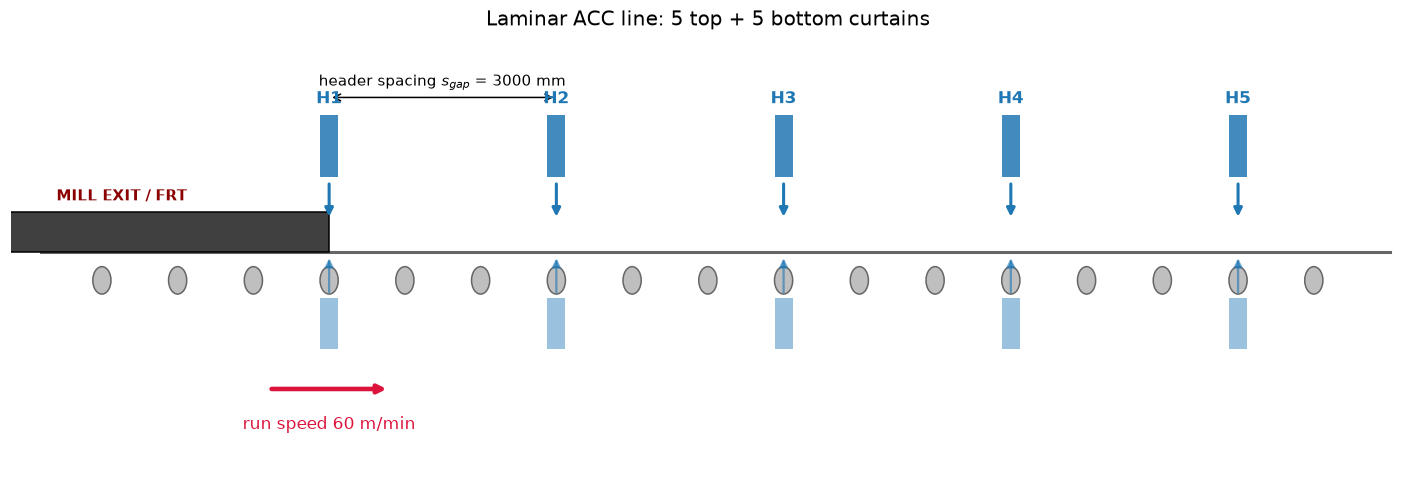

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.5))
v_ms, s_gap_m = v / 60.0, s_gap * 1e-3
plate_len = L * 1e-3
first_hdr = 2.0                                    # schematic position of header 1 [m]
hdr_x = [first_hdr + j * s_gap_m for j in range(n_cur)]

# run-out table rollers
for xr in np.arange(-1.0, hdr_x[-1] + 1.5, 1.0):
    ax.add_patch(plt.Circle((xr, -0.55), 0.12, fc="0.75", ec="0.4", zorder=1))
ax.plot([-1.8, hdr_x[-1] + 2.0], [-0.30, -0.30], color="0.4", lw=2)

# plate (leading edge at header 1 at t = 0)
ax.add_patch(plt.Rectangle((hdr_x[0] - plate_len, -0.30), plate_len, 0.35,
                           fc="0.25", ec="k", zorder=3))
ax.annotate(f"plate {t_h:.0f} mm thick (exaggerated)", xy=(hdr_x[0] - plate_len / 2, -0.12),
            ha="center", color="white", fontsize=9, zorder=4)

# top and bottom curtains
for hx in hdr_x:
    ax.add_patch(plt.Rectangle((hx - 0.12, 0.35), 0.24, 0.55, fc="tab:blue", ec="none", alpha=0.85))
    ax.annotate("", xy=(hx, -0.02), xytext=(hx, 0.32),
                arrowprops=dict(arrowstyle="-|>", color="tab:blue", lw=2))
    ax.add_patch(plt.Rectangle((hx - 0.12, -1.15), 0.24, 0.45, fc="tab:blue", ec="none", alpha=0.45))
    ax.annotate("", xy=(hx, -0.33), xytext=(hx, -0.68),
                arrowprops=dict(arrowstyle="-|>", color="tab:blue", lw=1.5, alpha=0.6))

# annotations
ax.annotate("MILL EXIT / FRT", xy=(-1.6, 0.15), fontsize=10, fontweight="bold", color="darkred")
ax.annotate("", xy=(hdr_x[0] + 0.8, -1.5), xytext=(hdr_x[0] - 0.8, -1.5),
            arrowprops=dict(arrowstyle="-|>", color="crimson", lw=3))
ax.annotate(f"run speed {v:.0f} m/min", xy=(hdr_x[0], -1.85), ha="center", color="crimson")
ax.annotate("", xy=(hdr_x[1], 1.05), xytext=(hdr_x[0], 1.05),
            arrowprops=dict(arrowstyle="<->", color="k"))
ax.annotate(f"header spacing $s_{{gap}}$ = {s_gap:.0f} mm", xy=((hdr_x[0] + hdr_x[1]) / 2, 1.15),
            ha="center", fontsize=10)
for j, hx in enumerate(hdr_x):
    ax.annotate(f"H{j+1}", xy=(hx, 1.0), ha="center", color="tab:blue", fontweight="bold")
ax.set_xlim(-2.2, hdr_x[-1] + 2.2); ax.set_ylim(-2.2, 1.6)
ax.set_title(f"Laminar ACC line: {n_cur} top + {n_cur} bottom curtains", fontsize=13)
ax.axis("off"); fig.tight_layout()
fig.savefig(f"{FIGDIR}/schematic.png", dpi=150)
plt.show()

## 8 · Empirical pre-calculation

The empirical module sizes the cooling before the FDM runs: water flux first, then the heat transfer coefficient, then the Biot number, then the analytical time estimates. These set the FDM boundary condition and also provide its benchmarks.

Water flux                 :    66.67 L/m2/s
Empirical HTC  h_w         :     3548 W/m2/K
Tuning factor              :     1.00  -> applied HTC 3548 W/m2/K
Biot number    Bi          :    1.478  -> NOT lumped: internal gradients matter, FDM required
Lumped time to 600 degC      :     7.18 s
One curtain exposure       :     0.25 s -> surface 880 -> 758 degC (semi-infinite)
Heisler  zeta1=0.9836, C1=1.1524


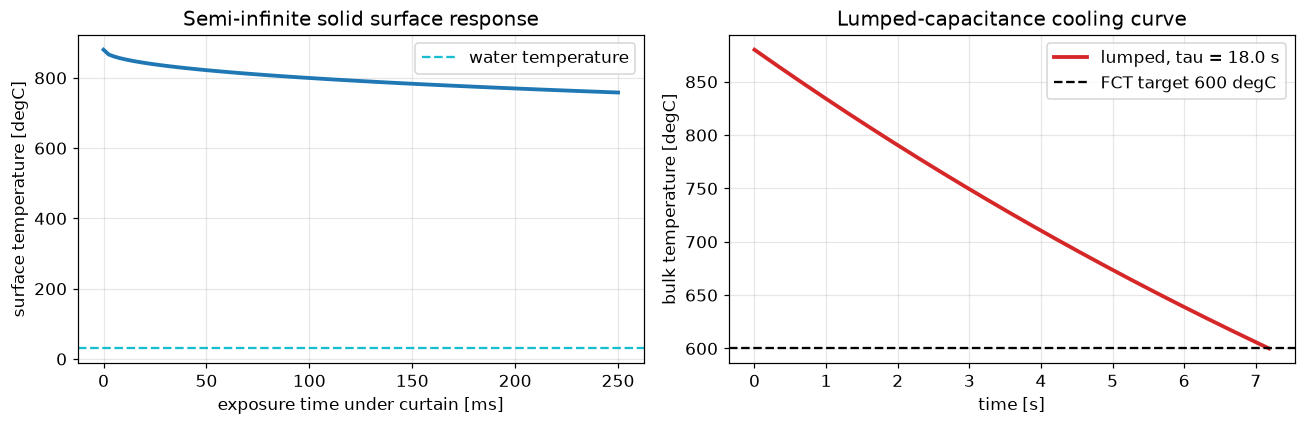

In [7]:
l_imp_m, t_h_m = l_imp * 1e-3, t_h * 1e-3

# 1. water flux and the empirical HTC correlation
W_flux   = (Q_header / 60.0) / (W * 1e-3 * l_imp_m)   # [L/m2/s]
W_flux_m = W_flux / 1000.0                            # [m3/m2/s]
C_corr, n_corr = 1.2e4, 0.45    # starting calibration, no source can be named for these two
h_w = C_corr * W_flux_m ** n_corr                     # [W/m2/K]
h_w_tuned = tune_factor * h_w                         # tuned HTC actually applied

# 2. Biot number
Bi = h_w_tuned * (t_h_m / 2) / k

# 3. lumped capacitance, exact only while Bi < 0.1
tau_lump = rho * cp * (t_h_m / 2) / h_w_tuned         # time constant [s]
t_lump   = tau_lump * np.log((FRT - Tw) / (FCT_tgt - Tw))   # time to FCT target [s]

# 4. semi-infinite solid surface response during one curtain pass
def Ts_semiinf(t):
    b = h_w_tuned * np.sqrt(alpha * t) / k
    return FRT + (Tw - FRT) * (1.0 - np.exp(b ** 2) * erfc(b))
t_exp   = l_imp_m / v_ms                              # one curtain exposure time [s]
Ts_1hdr = Ts_semiinf(t_exp)

# 5. Heisler one-term approximation, solving zeta*tan(zeta) = Bi
lo, hi = 1e-9, pi / 2 - 1e-9
for _ in range(200):
    mid = 0.5 * (lo + hi)
    if mid * tan(mid) > Bi: hi = mid
    else: lo = mid
zeta1 = 0.5 * (lo + hi)
C1 = 4 * np.sin(zeta1) / (2 * zeta1 + np.sin(2 * zeta1))

print(f"Water flux                 : {W_flux:8.2f} L/m2/s")
print(f"Empirical HTC  h_w         : {h_w:8.0f} W/m2/K")
print(f"Tuning factor              : {tune_factor:8.2f}  -> applied HTC {h_w_tuned:.0f} W/m2/K")
print(f"Biot number    Bi          : {Bi:8.3f}  -> " +
      ("lumped OK (Bi < 0.1)" if Bi < 0.1 else "NOT lumped: internal gradients matter, FDM required"))
print(f"Lumped time to {FCT_tgt:.0f} degC      : {t_lump:8.2f} s")
print(f"One curtain exposure       : {t_exp:8.2f} s -> surface {FRT:.0f} -> {Ts_1hdr:.0f} degC (semi-infinite)")
print(f"Heisler  zeta1={zeta1:.4f}, C1={C1:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ts = np.linspace(0, t_exp, 100)
ax1.plot(ts * 1e3, [Ts_semiinf(x) for x in ts], lw=2.5, color="tab:blue")
ax1.axhline(Tw, color="tab:cyan", ls="--", label="water temperature")
ax1.set_xlabel("exposure time under curtain [ms]"); ax1.set_ylabel("surface temperature [degC]")
ax1.set_title("Semi-infinite solid surface response"); ax1.legend()

tl = np.linspace(0, t_lump, 200)
ax2.plot(tl, Tw + (FRT - Tw) * np.exp(-tl / tau_lump), lw=2.5, color="tab:red",
         label=f"lumped, tau = {tau_lump:.1f} s")
ax2.axhline(FCT_tgt, color="k", ls="--", label=f"FCT target {FCT_tgt:.0f} degC")
ax2.set_xlabel("time [s]"); ax2.set_ylabel("bulk temperature [degC]")
ax2.set_title("Lumped-capacitance cooling curve"); ax2.legend()
fig.tight_layout(); fig.savefig(f"{FIGDIR}/empirical.png", dpi=150)
plt.show()

## 9 · Tuning factor: matching the model to plant reality

Real ACC lines rarely behave exactly as the textbook correlations predict. Surface scale, water pressure and flux distribution across the header, curtain alignment, plate roughness and recalescence all shift the effective cooling severity. The tuning factor rescales every water-side heat transfer coefficient:

$$h_{w,\,eff} = \mathrm{tune\_factor} \times h_w$$

Setting `tune_factor` above 1 means the line cools more severely than predicted. Setting it below 1 means it cools less severely.

If you have a measured finish cooling temperature, from a core thermocouple or an exit pyrometer, the calibration tool below finds the tuning factor that reproduces it. It runs a fast 1-D through-thickness solver with the same physics and the same curtain schedule at the plate centre, so the search takes seconds rather than a full 3-D run per trial.

Predicted core FCT (factor = 1.00) : 809.1 degC
Measured core FCT                  : 780.0 degC
Calibrated tuning factor           : 1.812
Check with calibrated factor       : 780.0 degC
-> set tune_factor = 1.812 in the inputs cell for the full 3-D run


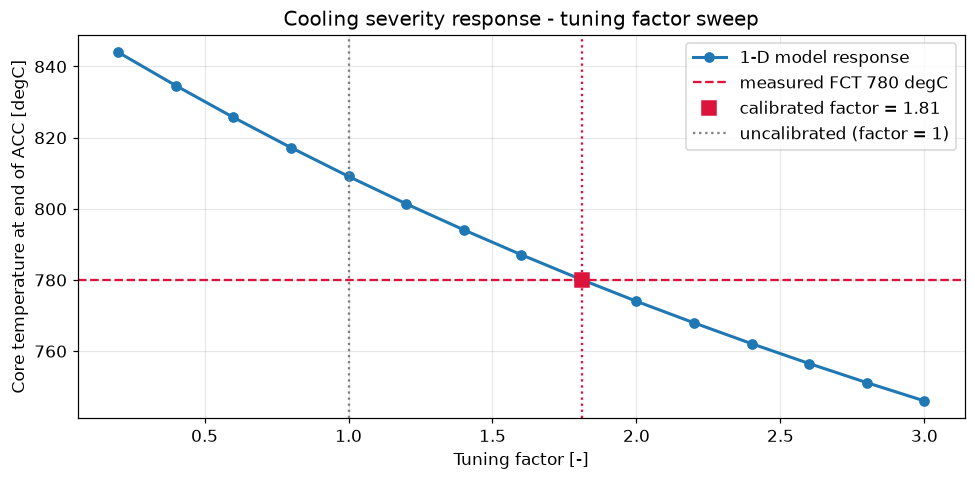

In [8]:
# the 1-D through-thickness solver used to search the tuning factor
def solve_core_1d(factor, n1d=51):
    """Core temperature at end of ACC - 1-D through thickness, plate-centre schedule."""
    h1  = factor * h_w
    dx1 = t_h * 1e-3 / (n1d - 1)
    # interior and surface limit together: the sweep below reaches factors where the surface
    # node governs the step, and taking only the interior limit made it unstable there
    dt1 = 0.8 / (2 * alpha / dx1**2 + 2 * h1 / (rho * cp * dx1))
    v1  = v / 60.0
    sg  = s_gap * 1e-3
    lim = l_imp * 1e-3
    t_end1 = (L * 1e-3 + (n_cur - 1) * sg + lim / 2) / v1
    x_c = L * 1e-3 / 2
    half = lim / 2.0
    TinfK = Tinf + 273.15
    T1 = np.full(n1d, FRT)
    t = 0.0
    while t < t_end1:
        # exposure at the plate centre for this step. The curtain band sweeps v1*dt1 per step,
        # so the fraction of the step the node is under water is an overlap rather than a flag
        lo = np.array([v1 * t - j * sg for j in range(n_cur)])
        ov = np.clip(np.minimum(x_c + half, lo + v1 * dt1) - np.maximum(x_c - half, lo),
                     0.0, v1 * dt1)
        f_wet = float(ov.max() / (v1 * dt1))
        T1K = T1 + 273.15
        h_rad = eps * SIGMA * (T1K**2 + TinfK**2) * (T1K + TinfK)     # absolute, not degC
        h_dry = h_air + h_rad[0]
        q0 = f_wet * h1 * (Tw - T1[0]) + (1.0 - f_wet) * h_dry * (Tinf - T1[0])
        q1 = f_wet * h1 * (Tw - T1[-1]) + (1.0 - f_wet) * h_dry * (Tinf - T1[-1])
        Tn = T1.copy()
        Tn[1:-1] = T1[1:-1] + dt1 * alpha * (T1[2:] - 2 * T1[1:-1] + T1[:-2]) / dx1**2
        Tn[0]  = T1[0]  + dt1 * (2 * alpha / dx1**2 * (T1[1]  - T1[0])  + 2 * q0 / (rho * cp * dx1))
        Tn[-1] = T1[-1] + dt1 * (2 * alpha / dx1**2 * (T1[-2] - T1[-1]) + 2 * q1 / (rho * cp * dx1))
        T1 = Tn
        t += dt1
    return T1[(n1d - 1) // 2]

FCT_measured = 780.0    # <-- replace with your plant measurement (core FCT at ACC exit, degC)

def calibrate(FCT_meas, lo=0.1, hi=5.0, tol=1e-3):
    """Bisection on the tuning factor to match a measured core FCT (monotonic: higher factor = cooler)."""
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if solve_core_1d(mid) > FCT_meas: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi)

f_cal = calibrate(FCT_measured)
print(f"Predicted core FCT (factor = 1.00) : {solve_core_1d(1.0):.1f} degC")
print(f"Measured core FCT                  : {FCT_measured:.1f} degC")
print(f"Calibrated tuning factor           : {f_cal:.3f}")
print(f"Check with calibrated factor       : {solve_core_1d(f_cal):.1f} degC")
print("-> set tune_factor = {:.3f} in the inputs cell for the full 3-D run".format(f_cal))

fs = np.linspace(0.2, 3.0, 15)
fcts = [solve_core_1d(f) for f in fs]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(fs, fcts, "o-", lw=2, label="1-D model response")
ax.axhline(FCT_measured, color="crimson", ls="--", label=f"measured FCT {FCT_measured:.0f} degC")
ax.axvline(f_cal, color="crimson", ls=":")
ax.plot(f_cal, FCT_measured, "s", color="crimson", ms=9, label=f"calibrated factor = {f_cal:.2f}")
ax.axvline(1.0, color="gray", ls=":", label="uncalibrated (factor = 1)")
ax.set_xlabel("Tuning factor [-]"); ax.set_ylabel("Core temperature at end of ACC [degC]")
ax.set_title("Cooling severity response - tuning factor sweep"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIGDIR}/tuning.png", dpi=150)
plt.show()

## 10 · The 3-D finite difference simulation

Half the width is modelled, by symmetry. The curtains sweep over the fixed plate. Under each curtain the surface sees $h_w$, and everywhere else it sees air convection and radiation. The solver samples the four depths at the plate centre and stores full-field snapshots for the contour maps.

In [9]:
# 3-D explicit finite difference solver. The plate is held fixed and the curtains sweep over it.

# computational grid, half the width by symmetry
dx_t = t_h * 1e-3 / (n_t - 1)
dy_w = W * 1e-3 / 2 / (n_w - 1)
dx_l = L * 1e-3 / (n_l - 1)
x_t = np.linspace(0, t_h * 1e-3, n_t)      # depth from TOP surface [m]
y_w = np.linspace(0, W * 1e-3 / 2, n_w)    # side edge -> centreline [m]
x_l = np.linspace(0, L * 1e-3, n_l)        # leading -> trailing edge [m]

# time step, from the stability criterion
# The tightest node is a surface node on the side edge: it takes conduction in all three
# directions and two convective faces at once, so its bound carries the lateral terms too.
dt_cond = 1.0 / (2 * alpha * (1 / dx_t**2 + 1 / dy_w**2 + 1 / dx_l**2))
h_max   = max(h_w_tuned, h_film * tune_factor if boiling_regime else 0.0)
h_edge  = h_air + eps * SIGMA * ((FRT + 273.15)**2 + (Tinf + 273.15)**2) * ((FRT + 273.15) + (Tinf + 273.15))
dt_surf = 1.0 / (2 * alpha * (1 / dx_t**2 + 1 / dy_w**2 + 1 / dx_l**2)
                 + 2 * h_max / (rho * cp * dx_t) + 2 * h_edge / (rho * cp * dy_w))
dt = 0.8 * min(dt_cond, dt_surf)

# moving-curtain schedule
v_ms = v / 60.0
hdr_shift = np.arange(n_cur) * s_gap * 1e-3            # (j-1)*s_gap [m]
l_imp_m = l_imp * 1e-3

def water_fraction(t, dt_step):
    """fraction of the step each length node spends under any curtain.

    A yes-or-no mask quantises the exposure to whole steps, and the plate advances 61 mm per
    step against a 50 mm grid, so neighbouring nodes would pick up four or five wet steps for
    the same 250 mm band and differ by a fifth of the dose. Overlapping the swept band with
    each node's window gives the exposure directly and takes that quantisation out.
    """
    c0 = v_ms * t - hdr_shift                      # curtain centres at the start of the step
    travel = v_ms * dt_step
    half = l_imp_m / 2.0
    frac = np.zeros_like(x_l)
    for j in range(n_cur):
        lo = c0[j]
        hi = lo + travel
        overlap = np.clip(np.minimum(x_l + half, hi) - np.maximum(x_l - half, lo), 0.0, travel)
        frac = np.maximum(frac, overlap / travel)
    return frac

# timeline
t_acc_end = (L * 1e-3 + (n_cur - 1) * s_gap * 1e-3 + l_imp_m / 2) / v_ms
t_end     = t_acc_end + t_post
n_steps   = int(np.ceil(t_end / dt))

# sampling locations
i_q  = int(round((n_t - 1) * 0.25))     # quarter depth
i_t3 = int(round((n_t - 1) / 3))        # one-third depth
i_c  = (n_t - 1) // 2                   # core
j_c, k_c = (n_w - 1) // 2, (n_l - 1) // 2

T = np.full((n_t, n_w, n_l), FRT)
t_hist = [0.0]
Ts_h, Tq_h, T3_h, Tc_h = [FRT], [FRT], [FRT], [FRT]
snap_targets = [f * t_acc_end for f in (0.25, 0.5, 0.75, 1.0)] + [t_end]
snaps, snap_idx = [], 0
frame_every = max(1, n_steps // 40)
frames = [(0.0, T[:, j_c, :].copy())]

print(f"Grid {n_t} x {n_w} x {n_l} nodes | dt = {dt:.4f} s | {n_steps} steps "
      f"(ACC ends at {t_acc_end:.2f} s) | h_w applied = {h_w_tuned:.0f} W/m2/K (tune {tune_factor:.2f})")
for step in range(1, n_steps + 1):
    t = step * dt
    wet = water_fraction(t - dt, dt)                      # exposure over this step
    TK, TinfK = T + 273.15, Tinf + 273.15                 # radiation needs absolute temperature
    h_rad = eps * SIGMA * (TK**2 + TinfK**2) * (TK + TinfK)

    # second differences, one-sided at the faces and zero flux at the symmetry plane
    d2x = np.empty_like(T)
    d2x[1:-1] = (T[2:] - 2 * T[1:-1] + T[:-2]) / dx_t**2
    d2x[0]    = 2 * (T[1]  - T[0])  / dx_t**2
    d2x[-1]   = 2 * (T[-2] - T[-1]) / dx_t**2
    d2y = np.empty_like(T)
    d2y[:, 1:-1, :] = (T[:, 2:] - 2 * T[:, 1:-1] + T[:, :-2]) / dy_w**2
    d2y[:, 0, :]    = 2 * (T[:, 1]  - T[:, 0])  / dy_w**2
    d2y[:, -1, :]   = 2 * (T[:, -2] - T[:, -1]) / dy_w**2
    d2z = np.empty_like(T)
    d2z[:, :, 1:-1] = (T[:, :, 2:] - 2 * T[:, :, 1:-1] + T[:, :, :-2]) / dx_l**2
    d2z[:, :, 0]    = 2 * (T[:, :, 1]  - T[:, :, 0])  / dx_l**2
    d2z[:, :, -1]   = 2 * (T[:, :, -2] - T[:, :, -1]) / dx_l**2

    Tn = T + dt * alpha * (d2x + d2y + d2z)

    # convection and radiation at the faces
    hw = np.where(T[0] > T_leid, h_film, h_nuc) * tune_factor if boiling_regime else h_w_tuned
    f_wet = wet[None, :]
    # the wetted part of the step exchanges with the water, the rest with the air
    q_top = f_wet * hw * (Tw - T[0]) + (1.0 - f_wet) * (h_air + h_rad[0]) * (Tinf - T[0])
    q_bot = f_wet * hw * (Tw - T[-1]) + (1.0 - f_wet) * (h_air + h_rad[-1]) * (Tinf - T[-1])
    Tn[0]       += dt * 2 / (rho * cp * dx_t) * q_top
    Tn[-1]      += dt * 2 / (rho * cp * dx_t) * q_bot
    Tn[:, -1, :] += dt * 2 / (rho * cp * dy_w) * (h_air + h_rad[:, -1, :]) * (Tinf - T[:, -1, :])
    Tn[:, :, 0]  += dt * 2 / (rho * cp * dx_l) * (h_air + h_rad[:, :, 0])  * (Tinf - T[:, :, 0])
    Tn[:, :, -1] += dt * 2 / (rho * cp * dx_l) * (h_air + h_rad[:, :, -1]) * (Tinf - T[:, :, -1])
    T = Tn

    t_hist.append(t)
    Ts_h.append(T[0, j_c, k_c]); Tq_h.append(T[i_q, j_c, k_c])
    T3_h.append(T[i_t3, j_c, k_c]); Tc_h.append(T[i_c, j_c, k_c])

    while snap_idx < len(snap_targets) and t >= snap_targets[snap_idx] - dt / 2:
        snaps.append((snap_targets[snap_idx], T.copy())); snap_idx += 1
    if step % frame_every == 0:
        frames.append((t, T[:, j_c, :].copy()))
    if step % max(1, n_steps // 10) == 0:
        print(f"  step {step:5d}/{n_steps}  t = {t:6.2f} s  T_core = {T[i_c, j_c, k_c]:7.1f} C")

t_hist = np.array(t_hist)
Ts_h, Tq_h, T3_h, Tc_h = map(np.array, (Ts_h, Tq_h, T3_h, Tc_h))
frames_t = np.array([f[0] for f in frames]); frames_T = np.array([f[1] for f in frames])
print(f"Done. min(T) = {T.min():.1f} C (stability ok if >= {Tw} C)")

Grid 26 x 201 x 241 nodes | dt = 0.0587 s | 923 steps (ACC ends at 24.12 s) | h_w applied = 3548 W/m2/K (tune 1.00)


  step    92/923  t =   5.40 s  T_core =   877.5 C


  step   184/923  t =  10.80 s  T_core =   862.9 C


  step   276/923  t =  16.20 s  T_core =   839.7 C


  step   368/923  t =  21.59 s  T_core =   815.8 C


...

  step   552/923  t =  32.39 s  T_core =   796.5 C


  step   644/923  t =  37.79 s  T_core =   790.3 C


  step   736/923  t =  43.19 s  T_core =   784.4 C


  step   828/923  t =  48.59 s  T_core =   778.6 C


  step   920/923  t =  53.98 s  T_core =   772.9 C
Done. min(T) = 696.9 C (stability ok if >= 30.0 C)


## 11 · Temperature evolution at the plate centre

The headline plot is the four depths against time. Blue bands mark each curtain passing the plate centre. Every passage pulls the surface temperature down while the core barely moves, which drives the surface-to-core differential up. After the last curtain, air cooling lets the temperatures converge.

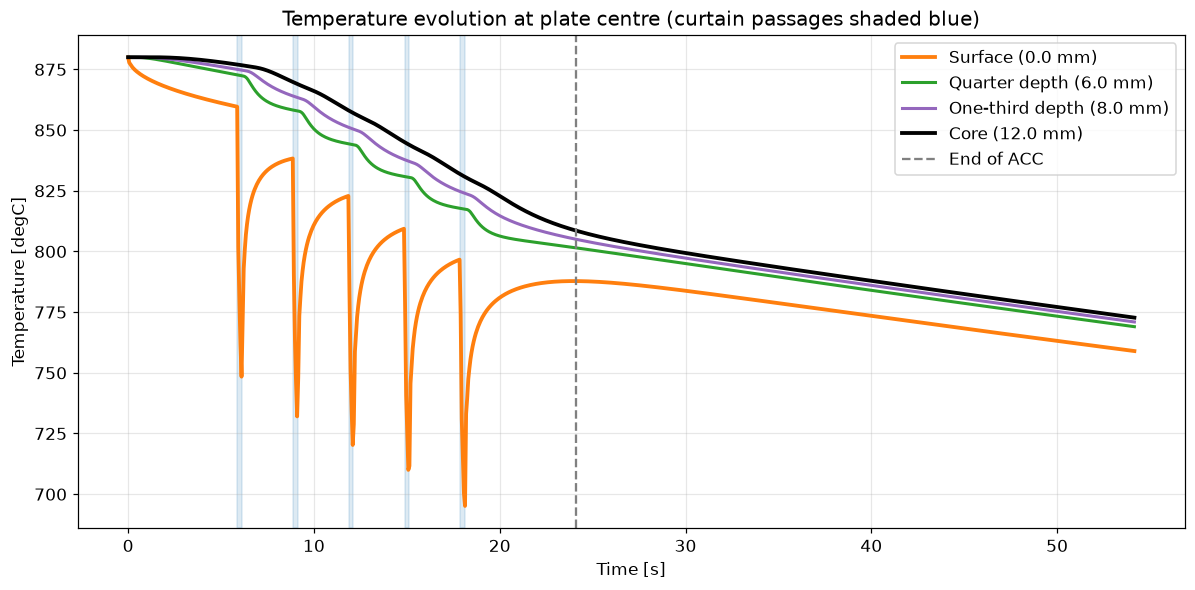

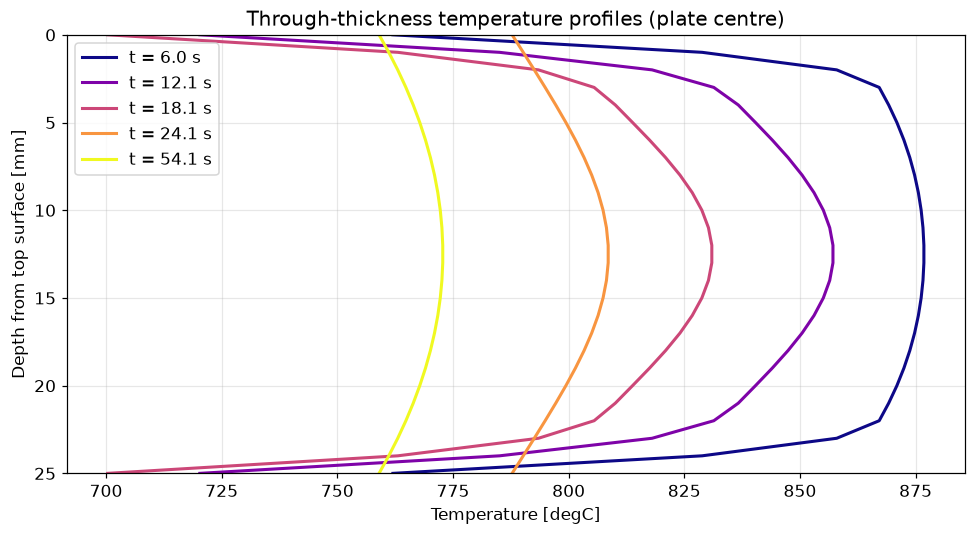

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(t_hist, Ts_h, lw=2.5, color="tab:orange", label=f"Surface ({x_t[0]*1e3:.1f} mm)")
ax.plot(t_hist, Tq_h, lw=2,   color="tab:green",  label=f"Quarter depth ({x_t[i_q]*1e3:.1f} mm)")
ax.plot(t_hist, T3_h, lw=2,   color="tab:purple", label=f"One-third depth ({x_t[i_t3]*1e3:.1f} mm)")
ax.plot(t_hist, Tc_h, lw=2.5, color="k",          label=f"Core ({x_t[i_c]*1e3:.1f} mm)")
ax.axvline(t_acc_end, color="gray", ls="--", label="End of ACC")
x_c = x_l[k_c]
for j in range(n_cur):
    t0 = (x_c + j * s_gap * 1e-3) / v_ms
    ax.axvspan(t0 - l_imp_m / (2 * v_ms), t0 + l_imp_m / (2 * v_ms), color="tab:blue", alpha=0.15)
ax.set_xlabel("Time [s]"); ax.set_ylabel("Temperature [degC]")
ax.set_title("Temperature evolution at plate centre (curtain passages shaded blue)")
ax.legend(loc="upper right"); fig.tight_layout()
fig.savefig(f"{FIGDIR}/evolution.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.cm.plasma
for idx, (tsnap, fld) in enumerate(snaps):
    ax.plot(fld[:, j_c, k_c], x_t * 1e3, lw=2, color=cmap(idx / (len(snaps) - 1)),
            label=f"t = {tsnap:.1f} s")
ax.set_ylim(t_h, 0)
ax.set_xlabel("Temperature [degC]"); ax.set_ylabel("Depth from top surface [mm]")
ax.set_title("Through-thickness temperature profiles (plate centre)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{FIGDIR}/profiles.png", dpi=150)
plt.show()

## 12 · 2-D spatial temperature fields

Full-field slices of the 3-D solution at four snapshots of the cooling:

- Thickness × Width, a mid-length section. The width gradient builds from the two side edges, which lose heat to air while the curtains quench the centre.
- Thickness × Length, the centre strip. The leading edge exits the ACC first, so the cooling front sweeps along the plate with the curtain train.
- Width × Length, the top surface and mid-thickness planes. This is the bow-wave pattern an ACC line is known for.

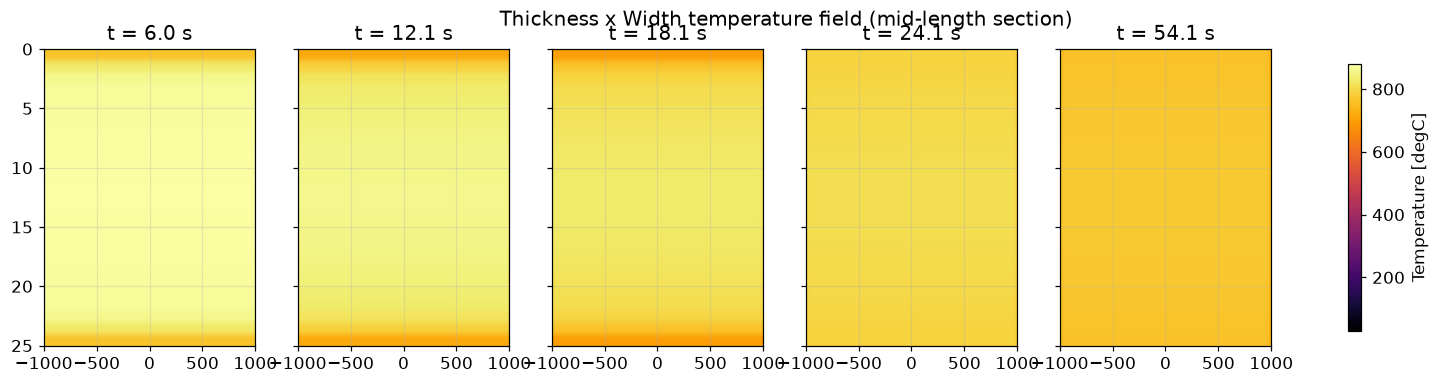

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharex=True, sharey=True)
for ax, (tsnap, fld) in zip(axes.ravel(), snaps):
    f2d = fld[:, :, k_c]                       # mid-length section (n_t x n_w)
    full = np.hstack([f2d[:, ::-1], f2d])      # mirror half width -> full width
    im = ax.imshow(full, extent=[-W / 2, W / 2, t_h, 0], aspect="auto",
                   cmap="inferno", vmin=Tw, vmax=FRT)
    ax.set_title(f"t = {tsnap:.1f} s")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Temperature [degC]", shrink=0.9)
fig.suptitle("Thickness x Width temperature field (mid-length section)", fontsize=13)
fig.savefig(f"{FIGDIR}/contour_thickness_width.png", dpi=150)
plt.show()

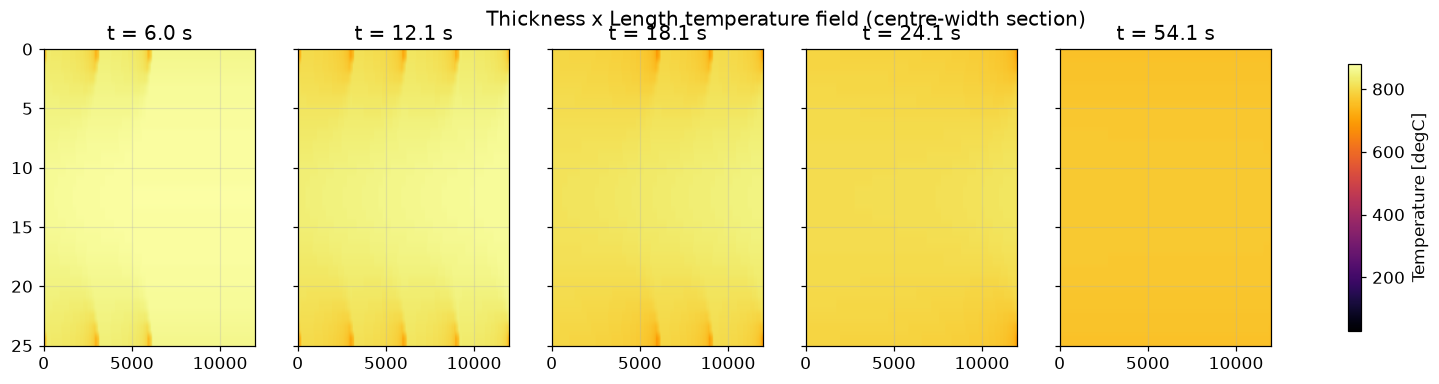

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharex=True, sharey=True)
for ax, (tsnap, fld) in zip(axes.ravel(), snaps):
    im = ax.imshow(fld[:, j_c, :], extent=[0, L, t_h, 0], aspect="auto",
                   cmap="inferno", vmin=Tw, vmax=FRT)
    ax.set_title(f"t = {tsnap:.1f} s")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Temperature [degC]", shrink=0.9)
fig.suptitle("Thickness x Length temperature field (centre-width section)", fontsize=13)
fig.savefig(f"{FIGDIR}/contour_thickness_length.png", dpi=150)
plt.show()

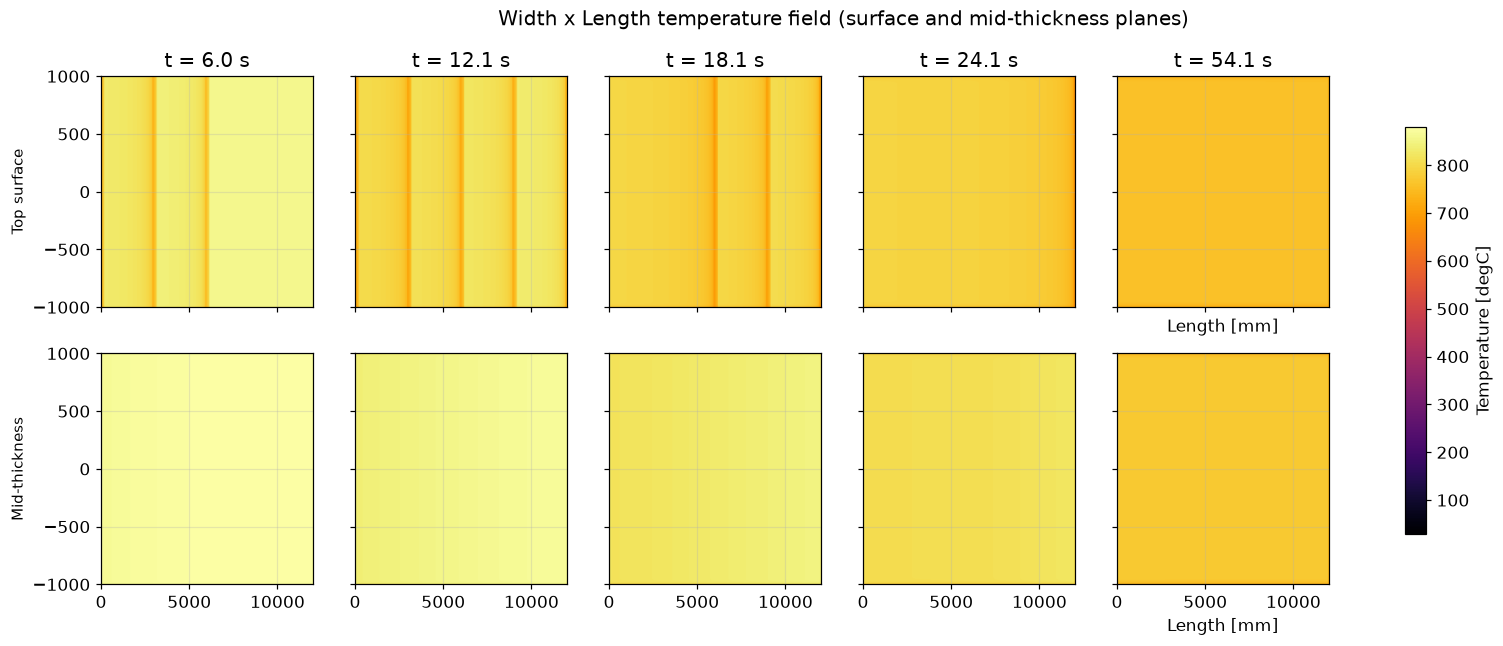

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True)
rows = [("Top surface", 0), ("Mid-thickness", i_c)]
for r, (rname, ii) in enumerate(rows):
    for c_, (tsnap, fld) in enumerate(snaps):
        ax = axes[r, c_]
        full = np.vstack([fld[ii][::-1], fld[ii]])   # mirror half width
        im = ax.imshow(full, extent=[0, L, -W / 2, W / 2], origin="lower", aspect="auto",
                       cmap="inferno", vmin=Tw, vmax=FRT)
        if r == 0: ax.set_title(f"t = {tsnap:.1f} s")
        if c_ == 0: ax.set_ylabel(rname, fontsize=10)
    ax.set_xlabel("Length [mm]")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Temperature [degC]", shrink=0.8)
fig.suptitle("Width x Length temperature field (surface and mid-thickness planes)", fontsize=13)
fig.savefig(f"{FIGDIR}/contour_width_length.png", dpi=150)
plt.show()

## 13 · Cooling rates and the surface-to-core differential

Cooling rate $CR=-dT/dt$ at the four depths, and the differential $\Delta T = T_{surface}-T_{core}$, which drives residual stress, distortion and property gradients through the plate.

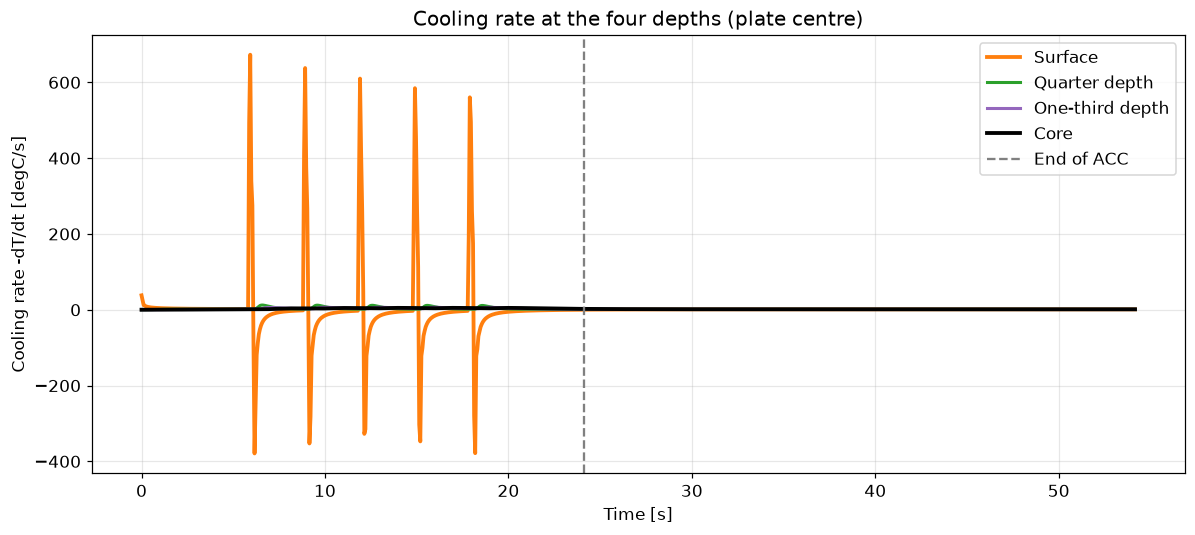

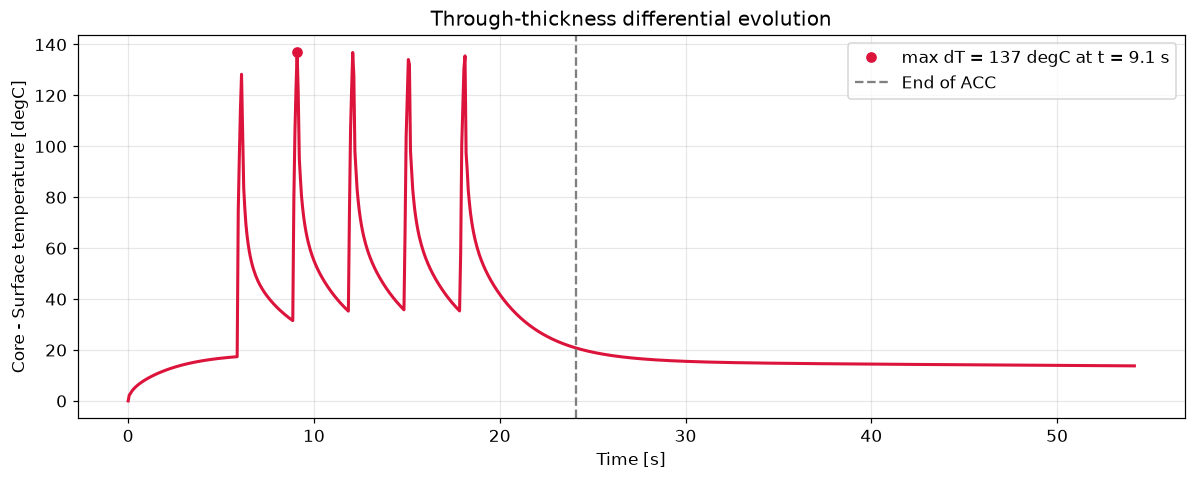

In [14]:
CRs = -np.gradient(np.vstack([Ts_h, Tq_h, T3_h, Tc_h]), t_hist, axis=1)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t_hist, CRs[0], lw=2.5, color="tab:orange", label="Surface")
ax.plot(t_hist, CRs[1], lw=2,   color="tab:green",  label="Quarter depth")
ax.plot(t_hist, CRs[2], lw=2,   color="tab:purple", label="One-third depth")
ax.plot(t_hist, CRs[3], lw=2.5, color="k",          label="Core")
ax.axvline(t_acc_end, color="gray", ls="--", label="End of ACC")
ax.set_xlabel("Time [s]"); ax.set_ylabel("Cooling rate -dT/dt [degC/s]")
ax.set_title("Cooling rate at the four depths (plate centre)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{FIGDIR}/cooling_rate.png", dpi=150)
plt.show()

dT = Tc_h - Ts_h     # core minus surface: positive while the surface is colder
imax = int(np.argmax(dT))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(t_hist, dT, lw=2, color="crimson")
ax.plot(t_hist[imax], dT[imax], "o", color="crimson",
        label=f"max dT = {dT[imax]:.0f} degC at t = {t_hist[imax]:.1f} s")
ax.axvline(t_acc_end, color="gray", ls="--", label="End of ACC")
ax.set_xlabel("Time [s]"); ax.set_ylabel("Core - Surface temperature [degC]")
ax.set_title("Through-thickness differential evolution"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIGDIR}/dt_surface_core.png", dpi=150)
plt.show()

In [15]:
# the same cooling rates as numbers, in degC/s
depth_names = ["Surface", "Quarter depth", "One-third depth", "Core"]
depth_series = [Ts_h, Tq_h, T3_h, Tc_h]
i_acc = int(np.argmin(np.abs(t_hist - t_acc_end)))

rows = ["| Depth | Peak [degC/s] | Mean over the ACC pass [degC/s] | Mean while air cooling [degC/s] | Through 800 to 500 degC [degC/s] |",
        "|---|---|---|---|---|"]
cr_rows = []
for name, Tprof in zip(depth_names, depth_series):
    peak = float(np.max(-np.gradient(Tprof, t_hist)))
    acc_mean = (Tprof[0] - Tprof[i_acc]) / t_hist[i_acc]
    air_mean = (Tprof[i_acc] - Tprof[-1]) / (t_hist[-1] - t_hist[i_acc])
    Tr, tr = Tprof[::-1], t_hist[::-1]
    if Tprof[0] >= 800.0 and Tprof[-1] <= 500.0:
        mid = (800.0 - 500.0) / float(np.interp(500.0, Tr, tr) - np.interp(800.0, Tr, tr))
    else:
        mid = float("nan")
    cr_rows.append((name, peak, acc_mean, air_mean, mid))
    mid_txt = f"{mid:.1f}" if mid == mid else "not reached"
    rows.append(f"| {name} | {peak:.1f} | {acc_mean:.1f} | {air_mean:.2f} | {mid_txt} |")
rows += ["",
         f"The plate drops from {FRT:.0f} to about {Ts_h[i_acc]:.0f} degC at the surface and {Tc_h[i_acc]:.0f} degC "
         f"at the core over the {t_acc_end:.1f} s of cooling, so the rate the section actually experiences sits between "
         f"{cr_rows[-1][2]:.1f} and {cr_rows[0][2]:.1f} degC/s. The surface peak lasts a fraction of a second under each "
         "curtain and is the most grid-sensitive number in the model, since it follows from the water coefficient and the "
         "1 mm first cell rather than from a measured surface response.",
         "",
         f"No depth reaches 500 degC inside the simulated {t_hist[-1]:.0f} s, so the 800 to 500 degC window, the range the "
         "transformation cares about, lies outside this run. What the plate inherits from the ACC pass is the temperature "
         "field it hands to the cooling bed, and section 16 reads the phases off that."]
display(Markdown("### Cooling rates in degC/s\n\n" + "\n".join(rows)))


### Cooling rates in degC/s

| Depth | Peak [degC/s] | Mean over the ACC pass [degC/s] | Mean while air cooling [degC/s] | Through 800 to 500 degC [degC/s] |
|---|---|---|---|---|
| Surface | 672.8 | 3.8 | 0.96 | not reached |
| Quarter depth | 12.3 | 3.3 | 1.08 | not reached |
| One-third depth | 6.6 | 3.1 | 1.13 | not reached |
| Core | 4.9 | 3.0 | 1.19 | not reached |

The plate drops from 880 to about 788 degC at the surface and 809 degC at the core over the 24.1 s of cooling, so the rate the section actually experiences sits between 3.0 and 3.8 degC/s. The surface peak lasts a fraction of a second under each curtain and is the most grid-sensitive number in the model, since it follows from the water coefficient and the 1 mm first cell rather than from a measured surface response.

No depth reaches 500 degC inside the simulated 54 s, so the 800 to 500 degC window, the range the transformation cares about, lies outside this run. What the plate inherits from the ACC pass is the temperature field it hands to the cooling bed, and section 16 reads the phases off that.

## 14 · Watching the cooling sweep along the plate

Animation of the thickness × length plane. The hot core lingers long after the surfaces are quenched, and the cooled front sweeps from the leading edge to the trailing edge as the curtain train moves down the table.

In [16]:
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(frames_T[0], extent=[0, L, t_h, 0], aspect="auto",
               cmap="inferno", vmin=Tw, vmax=FRT)
cb = fig.colorbar(im, ax=ax, label="Temperature [degC]")
ax.set_xlabel("Plate length [mm]"); ax.set_ylabel("Depth [mm]")
def update(i):
    im.set_data(frames_T[i])
    ax.set_title(f"t = {frames_t[i]:.2f} s")
    return (im,)
from matplotlib import animation
anim = animation.FuncAnimation(fig, update, frames=len(frames_t), interval=120)
plt.close(fig)
try:
    display(HTML(anim.to_html5_video()))
except Exception as exc:
    print("ffmpeg unavailable in this runtime, showing key frames instead:", exc)
    fig2, axes2 = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
    picks = np.linspace(0, len(frames_t) - 1, 4).astype(int)
    for ax2, p in zip(axes2, picks):
        ax2.imshow(frames_T[p], extent=[0, L, t_h, 0], aspect="auto",
                   cmap="inferno", vmin=Tw, vmax=FRT)
        ax2.set_title(f"t = {frames_t[p]:.2f} s")
    plt.show()

## 15 · Validation and summary

The FDM is benchmarked against the estimates from section 8: the lumped capacitance solution, the Heisler one-term approximation and the semi-infinite surface response. One caveat applies to the first two. They assume the water coefficient acts continuously over the whole timeline, while the plate is under water for about a twentieth of it, so both of them over-predict the cooling and land below the FDM as lower bounds. Neither bounds the result from above, and the word for what they do is not bracketing. The semi-infinite expression is a different thing again: it gives the surface dip during one 0.25 s curtain contact, not a core temperature at the end of the pass, so it checks the early surface response rather than the FDM's exit value.

In [17]:
Fo_end  = alpha * t_acc_end / (t_h_m / 2) ** 2
T_lump_end  = Tw + (FRT - Tw) * np.exp(-t_acc_end / tau_lump)
T_heis_end  = Tw + (FRT - Tw) * C1 * np.exp(-zeta1 ** 2 * Fo_end)

dT = Tc_h - Ts_h     # core minus surface: positive while the surface is colder
imax = int(np.argmax(dT))
T_final = {
    "Surface":            T[0, j_c, k_c],
    "Quarter depth (1/4)": T[i_q, j_c, k_c],
    "One-third depth (1/3)": T[i_t3, j_c, k_c],
    "Core":               T[i_c, j_c, k_c],
}
stability_ok = T.min() >= Tw - 1e-6
surface_faster = Ts_h[-1] < Tc_h[-1] or dT[imax] > 0

display(Markdown(f"""
### Final state (after ACC + {t_post:.0f} s air cooling, plate centre)

| Position | Final temperature [degC] | Peak cooling rate [degC/s] |
|---|---|---|
| Surface ({x_t[0]*1e3:.1f} mm) | {T_final['Surface']:.1f} | {CRs[0].max():.1f} |
| Quarter depth ({x_t[i_q]*1e3:.1f} mm) | {T_final['Quarter depth (1/4)']:.1f} | {CRs[1].max():.1f} |
| One-third depth ({x_t[i_t3]*1e3:.1f} mm) | {T_final['One-third depth (1/3)']:.1f} | {CRs[2].max():.1f} |
| Core ({x_t[i_c]*1e3:.1f} mm) | {T_final['Core']:.1f} | {CRs[3].max():.1f} |

### Validation

| Check | Value | Verdict |
|---|---|---|
| Biot number | {Bi:.2f} | {'lumped valid' if Bi < 0.1 else 'FDM required (Bi > 0.1)'} |
| Tuning factor (water HTC scale) | {tune_factor:.2f} | {'calibrated to plant data' if tune_factor != 1.0 else 'uncalibrated (correlation as-is)'} |
| FDM core temperature at end of ACC | {Tc_h[np.argmin(np.abs(t_hist - t_acc_end))]:.1f} degC | n/a |
| Lumped-capacitance estimate at end of ACC | {T_lump_end:.1f} degC | {'agrees' if abs(T_lump_end - Tc_h[np.argmin(np.abs(t_hist - t_acc_end))]) < 50 else 'deviates (expected for Bi > 0.1)'} |
| Heisler one-term estimate at end of ACC | {T_heis_end:.1f} degC | benchmark |
| Semi-infinite surface after 1 curtain | {Ts_1hdr:.1f} degC | benchmark |
| Max surface-core differential | {dT[imax]:.1f} degC at t = {t_hist[imax]:.1f} s | n/a |
| Stability (min T >= water temp) | {T.min():.1f} degC | {'PASS' if stability_ok else 'FAIL'} |
| Surface cools faster than core | n/a | {'PASS' if surface_faster else 'FAIL'} |
"""))


### Final state (after ACC + 30 s air cooling, plate centre)

| Position | Final temperature [degC] | Peak cooling rate [degC/s] |
|---|---|---|
| Surface (0.0 mm) | 759.0 | 672.8 |
| Quarter depth (6.0 mm) | 769.0 | 12.3 |
| One-third depth (8.0 mm) | 770.9 | 6.6 |
| Core (12.0 mm) | 772.7 | 4.9 |

### Validation

| Check | Value | Verdict |
|---|---|---|
| Biot number | 1.48 | FDM required (Bi > 0.1) |
| Tuning factor (water HTC scale) | 1.00 | uncalibrated (correlation as-is) |
| FDM core temperature at end of ACC | 808.5 degC | n/a |
| Lumped-capacitance estimate at end of ACC | 252.2 degC | deviates (expected for Bi > 0.1) |
| Heisler one-term estimate at end of ACC | 437.0 degC | benchmark |
| Semi-infinite surface after 1 curtain | 758.2 degC | benchmark |
| Max surface-core differential | 137.0 degC at t = 9.1 s | n/a |
| Stability (min T >= water temp) | 696.9 degC | PASS |
| Surface cools faster than core | n/a | PASS |


## 16 · Reading the cooling curve against those temperatures

Every depth has its own thermal path, so every depth meets the transformation temperatures at a different moment and at a different rate. The physics gives the rate, the chemistry gives the thresholds, and where they cross is what the plate is made of.

The rates are quoted three ways. Peak is the steepest instant, which happens under a curtain as it passes. The mean over the ACC pass is what the bulk of the plate experiences. The 800 to 500 degC window is the range the transformation actually sees, so the rate through that window is the one to hold against $V_{c90}$.

What the comparison cannot do is kinetics. A threshold temperature says a phase is possible, not how much of it appears, because the amount depends on how long the steel sits in each temperature range, and that is what a CCT diagram encodes. Going further honestly means a measured CCT diagram for the grade, a calibrated transformation model, or a thermodynamic calculation in pycalphad. pycalphad answers a different question again: it gives the equilibrium phase fractions against temperature, needs a steel database to do it, and carries no kinetics either, so it would sharpen the thresholds above and leave the rate comparison exactly as it stands.


In [18]:
# the rate that governs the transformation is the one the plate carries once the curtains stop
def Ar3_at_rate(CR_per_s):
    """Mintz regression for the ferrite start temperature, valid between 10 and 200 degC/min."""
    CR_per_min = CR_per_s * 60.0
    if not (10.0 <= CR_per_min <= 200.0):
        return None
    return (862 - 182*c["C"] - 76.1*c["Mn"] + 1121*c["S"] - 1804*c["Nb"]
            + 1168*c["Ti"] - 2852*N_free - 0.084*CR_per_min)

def what_the_path_implies(Tprof, governing):
    T_end = Tprof[-1]
    if T_end > Ar3:
        return "above the ferrite start temperature, so austenitic at this point"
    if T_end > Bs:
        return (f"below Ar3, in the ferrite and pearlite range; {governing:.2f} degC/s against "
                f"Vc90 = {Vc90:.0f} degC/s rules out martensite")
    if T_end > Ms:
        return f"below Bs, into the bainite range at {governing:.2f} degC/s"
    return f"below Ms, at {governing:.2f} degC/s against Vc90 = {Vc90:.0f} degC/s"

rows = ["| Depth | Rate while air cooling [degC/s] | T at end of ACC [degC] | T at end of window [degC] | Ar3 at the ACC mean rate [degC] | What the path implies |",
        "|---|---|---|---|---|---|"]
for (name, Tprof), (_, peak, acc_mean, air_mean, mid) in zip(zip(depth_names, depth_series), cr_rows):
    ar3_at = Ar3_at_rate(acc_mean)
    ar3_txt = f"{ar3_at:.0f}" if ar3_at is not None else "outside the fitted range"
    rows.append(f"| {name} | {air_mean:.2f} | {Tprof[i_acc]:.0f} | {Tprof[-1]:.0f} | {ar3_txt} "
                f"| {what_the_path_implies(Tprof, air_mean)} |")
rows += ["",
         f"Nothing in the column above is a transformation, and the numbers say why. The whole section is between "
         f"{min(s[i_acc] for s in depth_series):.0f} and {max(s[i_acc] for s in depth_series):.0f} degC when the curtains stop, "
         f"which is under the Ar3 of {Ar3:.0f} degC but far above Bs at {Bs:.0f} degC and Ms at {Ms:.0f} degC, "
         f"and the rate from there on is under {max(r[3] for r in cr_rows):.1f} degC/s against the {Vc90:.0f} degC/s that "
         "90 percent martensite would need. Ferrite and pearlite is what this section can make.",
         "",
         f"The {cr_rows[0][1]:.0f} degC/s surface spike is real in the model but irrelevant to the phases: it happens while the surface is "
         f"still near {FRT:.0f} degC, well above the ferrite start temperature, and a cooling rate only decides the "
         "microstructure while the steel is inside the transformation range. This is the one place where the "
         "through-thickness spread is invisible: the depths differ by about "
         f"{max(s[i_acc] for s in depth_series) - min(s[i_acc] for s in depth_series):.0f} degC at the end of the ACC, "
         f"against {max(Tc_h - Ts_h):.0f} degC at the peak of the pass."]
display(Markdown("\n".join(rows)))


| Depth | Rate while air cooling [degC/s] | T at end of ACC [degC] | T at end of window [degC] | Ar3 at the ACC mean rate [degC] | What the path implies |
|---|---|---|---|---|---|
| Surface | 0.96 | 788 | 759 | outside the fitted range | below Ar3, in the ferrite and pearlite range; 0.96 degC/s against Vc90 = 207 degC/s rules out martensite |
| Quarter depth | 1.08 | 801 | 769 | 674 | below Ar3, in the ferrite and pearlite range; 1.08 degC/s against Vc90 = 207 degC/s rules out martensite |
| One-third depth | 1.13 | 805 | 771 | 675 | below Ar3, in the ferrite and pearlite range; 1.13 degC/s against Vc90 = 207 degC/s rules out martensite |
| Core | 1.19 | 809 | 773 | 675 | below Ar3, in the ferrite and pearlite range; 1.19 degC/s against Vc90 = 207 degC/s rules out martensite |

Nothing in the column above is a transformation, and the numbers say why. The whole section is between 788 and 809 degC when the curtains stop, which is under the Ar3 of 816 degC but far above Bs at 672 degC and Ms at 470 degC, and the rate from there on is under 1.2 degC/s against the 207 degC/s that 90 percent martensite would need. Ferrite and pearlite is what this section can make.

The 673 degC/s surface spike is real in the model but irrelevant to the phases: it happens while the surface is still near 880 degC, well above the ferrite start temperature, and a cooling rate only decides the microstructure while the steel is inside the transformation range. This is the one place where the through-thickness spread is invisible: the depths differ by about 21 degC at the end of the ACC, against 137 degC at the peak of the pass.

## 17 · A cooling time for every phase

The last piece is the one a mill actually asks for: for a given cooling time, which phases come out. The map below is a CCT-style read of the chemistry entered in section 1, with the mean cooling rate over 800 to 500 °C on the lower axis and the equivalent time from 800 to 500 degC on the upper one, since that is the way a transformation is usually specified.

Two warnings about reading it. The horizontal boundaries are drawn flat because $B_s$ and $M_s$ depend on the chemistry and only weakly on the rate, while the ferrite start line does move with the rate and is drawn as a curve. And it is a screening guide, not a measured diagram: the lines say which phases the steel is capable of forming, not how much of each one appears, and a rate only decides the microstructure while the steel is inside the transformation range.


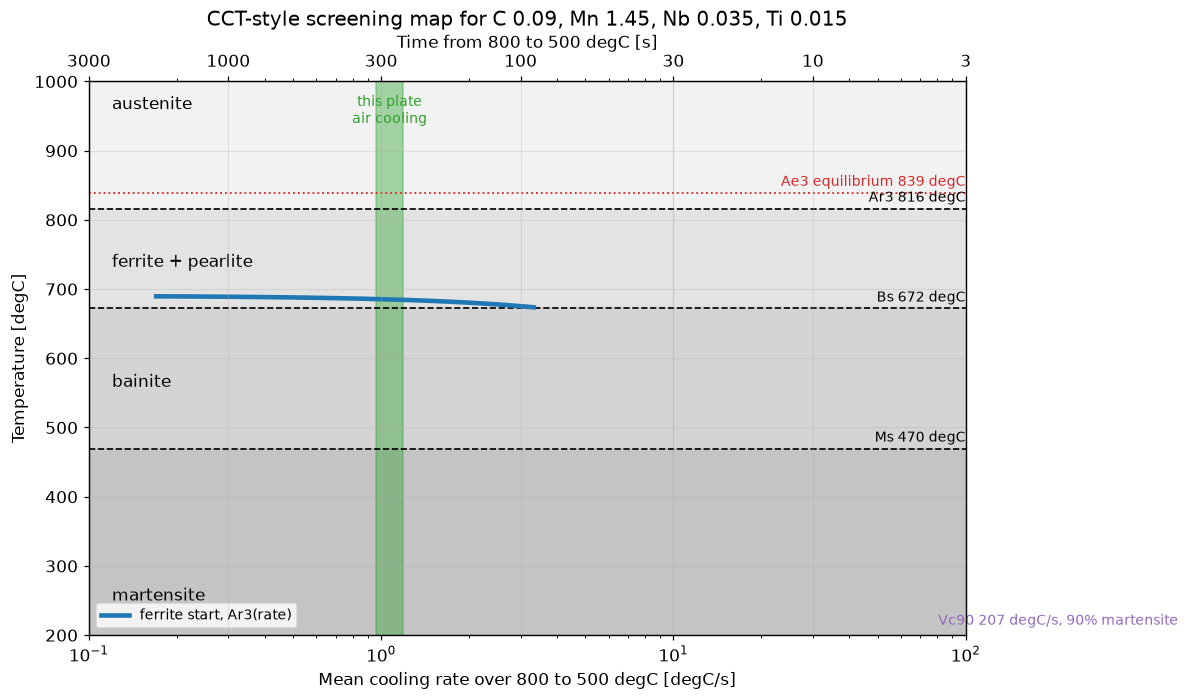

| Time 800 to 500 degC [s] | Rate [degC/s] | Ferrite start at that rate [degC] | What the chemistry gives |
|---|---|---|---|
| 5 | 60.00 | outside the fitted range | below Vc90, so no martensite; ferrite start line is outside its fitted range here |
| 10 | 30.00 | outside the fitted range | below Vc90, so no martensite; ferrite start line is outside its fitted range here |
| 20 | 15.00 | outside the fitted range | below Vc90, so no martensite; ferrite start line is outside its fitted range here |
| 40 | 7.50 | outside the fitted range | below Vc90, so no martensite; ferrite start line is outside its fitted range here |
| 80 | 3.75 | outside the fitted range | below Vc90, so no martensite; ferrite start line is outside its fitted range here |
| 150 | 2.00 | 680 | ferrite starts above Bs, so ferrite and pearlite |
| 300 | 1.00 | 685 | ferrite starts above Bs, so ferrite and pearlite |
| 600 | 0.50 | 688 | ferrite starts above Bs, so ferrite and pearlite |
| 1200 | 0.25 | 689 | ferrite starts above Bs, so ferrite and pearlite |

Across the band the regression was fitted on, 10 to 200 degC/min, the ferrite start line stays above Bs, so ferrite and pearlite is what this grade makes at the rates this line delivers. The margin at the top of that band is a few degrees, inside the regression's own scatter of about 18 degC, and outside the band nothing is claimed either way. Martensite would need 207 degC/s or more, roughly 193 times the rate the plate carries on the cooling bed, and bainite would need the steel to reach 672 degC before the ferrite reaction has taken the austenite.

Change the carbon or the manganese in section 1 and all of this moves: $B_s$ and $M_s$ fall as the alloying rises, the ferrite start line drops, and the martensite boundary $V_{c90}$ walks toward the rates a real line can reach. That is the run worth doing before quoting a cooling practice for a new grade.

In [19]:
# the same chemistry read against cooling time instead of depth
rate = np.logspace(np.log10(0.1), np.log10(100.0), 200)     # mean rate over 800-500 degC [degC/s]
t85 = 300.0 / rate                                          # time from 800 to 500 degC [s]
air_lo, air_hi = cr_rows[0][3], cr_rows[-1][3]              # the plate's own rate, from section 13

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.set_xscale("log"); ax.set_xlim(rate[0], rate[-1]); ax.set_ylim(200.0, 1000.0)
ax.axhspan(Ar3, 1000.0, color="0.95")
ax.axhspan(Bs, Ar3, color="0.89")
ax.axhspan(Ms, Bs, color="0.83")
ax.axhspan(200.0, Ms, color="0.77")
for y, lab in ((Ar3, f"Ar3 {Ar3:.0f} degC"), (Bs, f"Bs {Bs:.0f} degC"), (Ms, f"Ms {Ms:.0f} degC")):
    ax.axhline(y, color="k", lw=1.1, ls="--")
    ax.text(rate[-1], y + 10, lab, ha="right", fontsize=9)
if Ae3 is not None:
    ax.axhline(Ae3, color="tab:red", lw=1.2, ls=":")
    ax.text(rate[-1], Ae3 + 10, f"Ae3 equilibrium {Ae3:.0f} degC", ha="right", fontsize=9, color="tab:red")

r_fit = np.logspace(np.log10(0.17), np.log10(3.33), 40)     # the range the regression was fitted on
ax.plot(r_fit, [Ar3_at_rate(r) for r in r_fit], color="tab:blue", lw=3, label="ferrite start, Ar3(rate)")

ax.axvline(Vc90, color="tab:purple", lw=1.6, ls="--")
ax.text(Vc90, 215, f"Vc90 {Vc90:.0f} degC/s, 90% martensite", fontsize=9, color="tab:purple", ha="center")
ax.axvspan(air_lo, air_hi, color="tab:green", alpha=0.4)
ax.text(np.sqrt(air_lo * air_hi), 940, "this plate\nair cooling", fontsize=9, color="tab:green", ha="center")

ax.text(rate[0] * 1.2, 960, "austenite", fontsize=11)
ax.text(rate[0] * 1.2, (Bs + Ar3) / 2 - 12, "ferrite + pearlite", fontsize=11)
ax.text(rate[0] * 1.2, (Ms + Bs) / 2 - 12, "bainite", fontsize=11)
ax.text(rate[0] * 1.2, 250, "martensite", fontsize=11)
ax.set_xlabel("Mean cooling rate over 800 to 500 degC [degC/s]"); ax.set_ylabel("Temperature [degC]")
ax.set_title("CCT-style screening map for " + ", ".join(f"{k} {c.get(k, 0):g}" for k in ("C", "Mn", "Nb", "Ti")))
ax.legend(loc="lower left", fontsize=9)

top = ax.twiny(); top.set_xscale("log"); top.set_xlim(ax.get_xlim())
tick_t = np.array([3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0])
inside = (300.0 / tick_t >= rate[0]) & (300.0 / tick_t <= rate[-1])
top.set_xticks((300.0 / tick_t)[inside]); top.set_xticklabels([f"{t:g}" for t in tick_t[inside]])
top.set_xlabel("Time from 800 to 500 degC [s]")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/cct_screening.png", dpi=150); plt.show()

rows = ["| Time 800 to 500 degC [s] | Rate [degC/s] | Ferrite start at that rate [degC] | What the chemistry gives |",
        "|---|---|---|---|"]
for t in (5.0, 10.0, 20.0, 40.0, 80.0, 150.0, 300.0, 600.0, 1200.0):
    r = 300.0 / t
    ar3_at = Ar3_at_rate(r)
    if r >= Vc90:
        verdict = "at or above Vc90, so martensite is expected"
    elif ar3_at is None:
        verdict = "below Vc90, so no martensite; ferrite start line is outside its fitted range here"
    elif ar3_at > Bs:
        verdict = "ferrite starts above Bs, so ferrite and pearlite"
    else:
        verdict = "ferrite start below Bs, so bainite would come first"
    rows.append(f"| {t:g} | {r:.2f} | {'outside the fitted range' if ar3_at is None else f'{ar3_at:.0f}'} | {verdict} |")
rows += ["",
         f"Across the band the regression was fitted on, 10 to 200 degC/min, the ferrite start line stays above Bs, so "
         f"ferrite and pearlite is what this grade makes at the rates this line delivers. The margin at the top of that "
         f"band is a few degrees, inside the regression's own scatter of about 18 degC, and outside the band nothing is "
         f"claimed either way. Martensite would need {Vc90:.0f} degC/s or more, roughly "
         f"{Vc90/((air_lo + air_hi) / 2):.0f} times the rate the plate carries on the cooling bed, and bainite would need "
         f"the steel to reach {Bs:.0f} degC before the ferrite reaction has taken the austenite.",
         "",
         "Change the carbon or the manganese in section 1 and all of this moves: $B_s$ and $M_s$ fall as the alloying "
         "rises, the ferrite start line drops, and the martensite boundary $V_{c90}$ walks toward the rates a real line "
         "can reach. That is the run worth doing before quoting a cooling practice for a new grade."]
display(Markdown("\n".join(rows)))


## 18 · The story, in short

- The surface is quenched by every curtain passage, while the core barely notices a single one and follows only through conduction, so the differential peaks while the curtain train is still passing.
- Since $Bi \gg 0.1$, the lumped model is no use for design. The FDM resolves the quarter-depth and one-third-depth temperatures that sit between the two extremes.
- The cooling rate quoted in degC/s: the surface sees a peak of about 673 degC/s as a curtain passes, the section as a whole cools at 3.0 to 3.8 degC/s over the ACC pass, and the rate that then governs the transformation is the 0.96 to 1.19 degC/s of air cooling on the bed. The surface peak is the most grid-sensitive number in the model.
- The chemistry of the grade (C 0.09, Mn 1.45, Nb 0.035) puts $Ac_1$ at 728 degC, $Ac_3$ at 861 degC, $Ar_3$ at 816 degC, $B_s$ at 672 degC and $M_s$ at 470 degC, and 90 percent martensite would need 207 degC/s on this chemistry, which carries no boron. Since the section leaves the curtains between 788 and 809 degC and then cools at under 1.2 degC/s, the plate makes ferrite and pearlite; bainite never gets a look in.
- The same heat solved for equilibrium with pycalphad puts Ae3 at 839 degC and A1 at 684 degC, against the empirical Ac3 of 861 degC, Ar3 of 816 degC and Ac1 of 728 degC. Two independent routes landing within a few tens of degrees is the check worth having. The A1 gap is where the microalloying would show if the calculation carried it: the phase set holds no niobium carbide or nitride, so the niobium sits in solution there by construction and that number bounds the effect rather than measuring it.
- Section 17 turns the same chemistry round to cooling time: over the band the ferrite-start regression covers, the answer stays ferrite and pearlite, and outside that band the model stops claiming anything.
- Width and length gradients come from the side edges and from the leading and trailing edges losing heat to air, which shows up as cold rims in every contour.
- Change `t_h, W, L, n_cur, v, FRT, s_gap` in the inputs cell and re-run. The whole pipeline, from the empirical pre-calculation through the FDM to the contours, updates by itself.
- When plant measurements disagree with the prediction, calibrate the `tune_factor` (section 9) from a measured finish cooling temperature, and every downstream result carries the calibrated severity.

The transient thermal equations used here are in sections 4 and 5.